# EP1 - Técnicas Avanzadas de Machine Learning I (TLY1101)
**Integrantes:** Karla Hoch y Sebastián Huaiquimilla

**Dataset:** Oxford-IIIT Pet.

**Variante propia:** clasificación multiclase de 5 razas de gatos, comparando un subconjunto de razas **parecidas entre sí** con uno de razas **distintas entre sí**.

## 1. Definición del problema (IE1)
Una clínica veterinaria quiere agilizar el registro de pacientes. A partir de una fotografía de un gato, el sistema propone su **raza** para prellenar la ficha clínica (la raza condiciona controles preventivos y riesgos conocidos), y el personal confirma o corrige. Es una herramienta de **apoyo**, no de decisión.

### 1.1 Dataset y justificación
Se eligió el **Oxford-IIIT Pet Dataset** (37 razas de perros y gatos, unas 200 imágenes por raza, con variabilidad de fondo, postura e iluminación, y anotaciones oficiales que incluyen la raza). Razones:
1. **Coherencia con el negocio:** son fotografías de mascotas con la raza como etiqueta, que es lo que necesita la clínica. Los otros datasets propuestos (escenarios naturales, enfermedades de plantas, Los Simpson) no se relacionan con este problema.
2. **Dificultad realista para un MLP:** la variabilidad de fondo, tamaño del animal e iluminación permite observar las limitaciones de un MLP sobre píxeles.
3. **Permite construir subconjuntos controlados por raza**, necesarios para estudiar el efecto del parecido visual entre clases.

### 1.2 Variante propia del proyecto
"Perro vs. gato" es el ejemplo que da la pauta, por lo que se descartó. La variante propia combina estas decisiones:

- **Problema multiclase de 5 razas de gatos**, en lugar de clasificación binaria.
- **Dos subconjuntos disjuntos, ambos solo de gatos** (así la especie no es una variable que cambie entre ellos):
  - **PARECIDAS:** Birman, Ragdoll, Siamese, Persian, Maine_Coon. *Criterio:* Birman, Ragdoll y Siamese comparten el patrón *colorpoint* (cuerpo claro con cara, orejas y patas más oscuras); Persian y Maine_Coon se incluyen por su pelaje largo, un parecido más débil (ver sección 3).
  - **DISTINTAS:** Bombay, Sphynx, Russian_Blue, Bengal, Abyssinian. *Criterio:* cada raza difiere de las otras en color, textura o forma (negro liso, sin pelo, gris liso, manchas, pelo corto rojizo).
- **Cantidad limitada y pareja de imágenes por clase:** se usa la misma cantidad por raza en ambos subconjuntos (la menor disponible entre las 10 razas), sorteada con semilla propia.
- **Semilla propia** (`SEED_SPLIT`, distinta de la típica 42) y división estratificada 70/15/15.
- **Comparación entre subconjuntos:** toda la experimentación se hace sobre PARECIDAS; la configuración elegida se aplica después a DISTINTAS sin reajustarla.

**Hipótesis (escrita antes de entrenar):** el MLP logrará un mayor F1 macro en DISTINTAS que en PARECIDAS, porque un MLP sobre píxeles aplanados se apoya sobre todo en color y textura global y no en la forma local de rasgos (orejas, hocico). Si el desempeño resulta similar, también es un resultado válido y se analizará.

### 1.3 Objetivos
**General:** construir un MLP que clasifique la raza de un gato a partir de una fotografía, y evaluar críticamente su desempeño y limitaciones según el parecido visual entre razas.

**Específicos:**
1. Explorar y preparar los subconjuntos (calidad de datos, redimensionamiento, normalización, división estratificada).
2. Cuantificar con datos que el subconjunto PARECIDAS es realmente más parecido que DISTINTAS.
3. Implementar y justificar un MLP base, y compararlo con variantes (aumento de datos, learning rate, neuronas, profundidad, activación, batch, estandarización, dropout) usando varias semillas.
4. Evaluar con Accuracy, Precision, Recall, F1-Score y matriz de confusión, y analizar aciertos, errores y razas confundidas.
5. Contrastar el desempeño entre PARECIDAS y DISTINTAS, e identificar las limitaciones del MLP en imágenes.

### 1.4 KPIs
La línea base del azar con 5 clases balanceadas es **20% de accuracy**.
- **KPI principal:** F1-Score macro en el set de prueba ≥ **0,40** (el doble del azar), promedio de 5 semillas.
- **KPI secundario:** recall mínimo entre las 5 razas ≥ **0,20**, promedio de 5 semillas. Significa que ninguna raza queda ignorada por el modelo.

Se fijaron antes de entrenar y **no se modificarán después de ver los resultados**. Son metas modestas, acordes a un MLP sobre píxeles aplanados de 64x64 con ~129 imágenes de entrenamiento por raza.

### 1.5 Metodología (CRISP-DM)
| Fase | Dónde se aborda |
|---|---|
| 1. Comprensión del negocio | Sección 1: problema, objetivos, KPIs, hipótesis |
| 2. Comprensión de los datos | Secciones 2 y 3: carga, variante, EDA, calidad de datos |
| 3. Preparación de los datos | Secciones 2 y 4: muestreo, división, redimensionamiento, normalización, aumento, similitud entre razas |
| 4. Modelado | Secciones 5, 6 y 7: arquitectura, experimentos, selección, entrenamiento y curvas |
| 5. Evaluación | Secciones 8, 9 y 10: métricas en prueba, errores, contraste entre subconjuntos, KPIs |
| 6. Despliegue | No se despliega. El modelo se guarda en `models/` y se proponen mejoras (CNN, transfer learning) en la sección 11 |

### 1.6 Cómo reproducir
1. Abrir el notebook en Google Colab.
2. `Entorno de ejecución > Ejecutar todo`. El notebook descarga el dataset oficial y ejecuta todo el pipeline.
3. Las semillas están fijadas (`SEED_SPLIT` para el muestreo y la partición, y listas de semillas para la inicialización) y se activa el **modo determinista de TensorFlow** (`enable_op_determinism`). Una celda de la sección 5 verifica que dos entrenamientos con la misma semilla dan resultados idénticos. Aun así, otra versión de TensorFlow o distinto hardware (GPU o CPU) puede dar resultados levemente distintos, por eso **los resultados se reportan como media ± desviación estándar de varias semillas**.

### 1.7 Consideraciones éticas
- **Origen y uso de los datos:** el Oxford-IIIT Pet (Parkhi et al., 2012) se usa con fines académicos y se cita su fuente. Son fotografías de internet de mascotas; algunas pueden mostrar personas o lugares reconocibles al fondo, que no se usan ni se analizan.
- **Privacidad en un uso real:** en una clínica, las fotos y la ficha quedan asociadas a los dueños. Habría que pedir consentimiento, guardar las imágenes de forma segura y no usarlas para otros fines.
- **Sesgo y representatividad:** el dataset solo tiene razas definidas, con fotos de internet (en general bien encuadradas), y no incluye gatos mestizos, que son la mayoría en la práctica. Un modelo entrenado así rendirá peor con gatos que no se parezcan a esas fotos, y sus errores no se reparten parejo entre razas (se mide en las secciones 8 a 10).
- **Riesgo de uso:** la raza condiciona controles preventivos. Un error confirmado sin mirar podría llevar a registrar mal una ficha o a sugerir controles inadecuados. Por eso se plantea solo como apoyo, con confirmación del personal, y nunca como decisión automática.
- **Transparencia:** se reportan también los resultados que no cumplen los KPIs, junto con sus limitaciones, para no sobreestimar lo que el modelo puede hacer.

In [1]:
# ==========================================
# CONFIGURACIÓN GENERAL
# ==========================================
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"      # menos logs de TensorFlow/CUDA (debe ir antes de importar TF)

import random, time, warnings
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             f1_score, accuracy_score, recall_score)
from scipy.stats import binomtest
from PIL import Image

warnings.filterwarnings("ignore")
tf.get_logger().setLevel("ERROR")   # evita el warning de retracing de tf.function
print("TensorFlow:", tf.__version__)

# --- Semillas y parámetros (todo lo "ajustable" vive aquí) ---
SEED_SPLIT = 2604                 # semilla propia del grupo: muestreo y división de datos (cambiar si se desea)
SEEDS_EXP = [11, 22, 33]          # semillas de inicialización para la fase de experimentos (validación)
SEEDS_FINAL = [101, 102, 103, 104, 105]   # semillas para la evaluación final en prueba

random.seed(SEED_SPLIT); np.random.seed(SEED_SPLIT); tf.keras.utils.set_random_seed(SEED_SPLIT)

# Modo determinista: con la misma semilla y el mismo entorno, un entrenamiento da exactamente el mismo resultado.
# (La semilla sola no basta en GPU: el orden de las sumas en paralelo cambia entre ejecuciones.)
try:
    tf.config.experimental.enable_op_determinism()
    print("Modo determinista de TensorFlow: ACTIVADO")
except Exception as e:
    print("No se pudo activar el modo determinista:", e)

RES_BASE = 64                     # resolución de partida; la sección 6.3 la compara con 96 y 128
BATCH_SIZE = 32
EPOCAS_MAX = 150
PACIENCIA = 7

KPI_F1_MACRO = 0.40               # KPI principal (definido antes de entrenar)
KPI_RECALL_MIN = 0.20             # KPI secundario (definido antes de entrenar)

# Carpetas de salida (quedan listas para el repositorio)
for carpeta in ["images", "models", "resultados"]:
    os.makedirs(carpeta, exist_ok=True)

def guardar_fig(nombre):
    plt.savefig(f"images/{nombre}.png", dpi=150, bbox_inches="tight")

TensorFlow: 2.21.0
Modo determinista de TensorFlow: ACTIVADO


In [2]:
# ==========================================
# DESCARGA DEL DATASET OFICIAL (imágenes + anotaciones)
# ==========================================
!wget -q https://www.robots.ox.ac.uk/~vgg/data/pets/data/images.tar.gz
!wget -q https://www.robots.ox.ac.uk/~vgg/data/pets/data/annotations.tar.gz
!tar -xzf images.tar.gz
!tar -xzf annotations.tar.gz
print("Dataset listo.")

Dataset listo.


## 2. Datos, variante y división (IE1, IE2)
Se usan las **7.349 imágenes con anotación oficial** (`list.txt`); las 41 imágenes sin anotación que trae la carpeta descargada se excluyen, por lo que ya no hay diferencia entre la cifra de la pauta y la usada. La **raza** se obtiene del nombre del archivo (por ejemplo `Birman_12.jpg`) y se verifica que todas las razas elegidas sean gatos con la columna `especie` de las anotaciones.

**Muestreo:** de cada raza se sortean `N_POR_CLASE` imágenes con la semilla propia, donde `N_POR_CLASE` es la menor cantidad disponible entre las 10 razas. Así ambos subconjuntos quedan **balanceados y del mismo tamaño**, y no hace falta `class_weight`.

**División:** 70% entrenamiento, 15% validación y 15% prueba, **estratificada por raza**, con la semilla propia. El set de prueba se separa desde el inicio y la configuración final se eligió solo con validación; la única salvedad es que la ronda 2 se diseñó tras ver un resultado en prueba de una ejecución anterior (sección 6.2), así que la independencia del set de prueba no es total.

In [3]:
# ==========================================
# CARGA DE ANOTACIONES Y DEFINICIÓN DE LA VARIANTE
# ==========================================
cols = ["imagen", "clase_id", "especie", "raza_id"]          # especie: 1 = gato, 2 = perro
lista = pd.read_csv("/content/annotations/list.txt", comment="#", sep=" ", header=None, names=cols)
lista["raza"] = lista["imagen"].str.rsplit("_", n=1).str[0]
lista["ruta"] = "/content/images/" + lista["imagen"] + ".jpg"
print(f"Imágenes anotadas: {len(lista)} | razas: {lista['raza'].nunique()}")
assert lista["ruta"].map(os.path.exists).all(), "Faltan archivos de imagen"

PARECIDAS = ["Birman", "Ragdoll", "Siamese", "Persian", "Maine_Coon"]
DISTINTAS = ["Bombay", "Sphynx", "Russian_Blue", "Bengal", "Abyssinian"]

assert not set(PARECIDAS) & set(DISTINTAS), "Los subconjuntos deben ser disjuntos"
assert set(PARECIDAS + DISTINTAS) <= set(lista["raza"]), "Hay un nombre de raza que no existe"
assert (lista[lista["raza"].isin(PARECIDAS + DISTINTAS)]["especie"] == 1).all(), "Todas las razas deben ser gatos"

conteo = lista[lista["raza"].isin(PARECIDAS + DISTINTAS)]["raza"].value_counts()
print("\nImágenes disponibles por raza elegida:")
print(conteo.to_string())
N_POR_CLASE = int(conteo.min())
print(f"\nN_POR_CLASE (mínimo disponible) = {N_POR_CLASE}")

Imágenes anotadas: 7349 | razas: 37

Imágenes disponibles por raza elegida:
raza
Bengal          200
Birman          200
Sphynx          200
Maine_Coon      200
Persian         200
Ragdoll         200
Russian_Blue    200
Siamese         199
Abyssinian      198
Bombay          184

N_POR_CLASE (mínimo disponible) = 184


In [4]:
# Verificación de la cifra: imágenes en la carpeta vs. imágenes con anotación oficial
n_jpg = len([f for f in os.listdir("/content/images") if f.endswith(".jpg")])
print(f"Imágenes .jpg en la carpeta: {n_jpg} | con anotación oficial (list.txt): {len(lista)} | sin anotación: {n_jpg - len(lista)}")

Imágenes .jpg en la carpeta: 7390 | con anotación oficial (list.txt): 7349 | sin anotación: 41


In [5]:
# ==========================================
# MUESTREO BALANCEADO + DIVISIÓN ESTRATIFICADA 70/15/15
# ==========================================
def preparar_subconjunto(clases, n_por_clase, seed):
    rng = np.random.default_rng(seed)
    partes = []
    for c in clases:
        fc = lista[lista["raza"] == c].sort_values("imagen")      # orden fijo -> muestreo reproducible
        partes.append(fc.iloc[rng.permutation(len(fc))[:n_por_clase]])
    d = pd.concat(partes).reset_index(drop=True)
    d["y"] = d["raza"].map({c: i for i, c in enumerate(clases)})
    tr, tmp = train_test_split(d, test_size=0.30, stratify=d["y"], random_state=seed)
    va, te = train_test_split(tmp, test_size=0.50, stratify=tmp["y"], random_state=seed)
    return tr.reset_index(drop=True), va.reset_index(drop=True), te.reset_index(drop=True)

SPLITS = {}
for nombre, clases in [("parecidas", PARECIDAS), ("distintas", DISTINTAS)]:
    tr, va, te = preparar_subconjunto(clases, N_POR_CLASE, SEED_SPLIT)
    SPLITS[nombre] = dict(clases=clases, train=tr, val=va, test=te)
    print(f"{nombre:10s} -> train: {len(tr)} | val: {len(va)} | test: {len(te)} | clases: {clases}")

parecidas  -> train: 644 | val: 138 | test: 138 | clases: ['Birman', 'Ragdoll', 'Siamese', 'Persian', 'Maine_Coon']
distintas  -> train: 644 | val: 138 | test: 138 | clases: ['Bombay', 'Sphynx', 'Russian_Blue', 'Bengal', 'Abyssinian']


## 3. Análisis exploratorio (EDA) (IE2)
Las decisiones de preprocesamiento se toman mirando **solo el set de entrenamiento** de ambos subconjuntos, para no filtrar información de validación ni de prueba. Se revisan la distribución de clases, ejemplos visuales por raza, y la calidad de los archivos (dimensiones, modo de color, archivos corruptos).

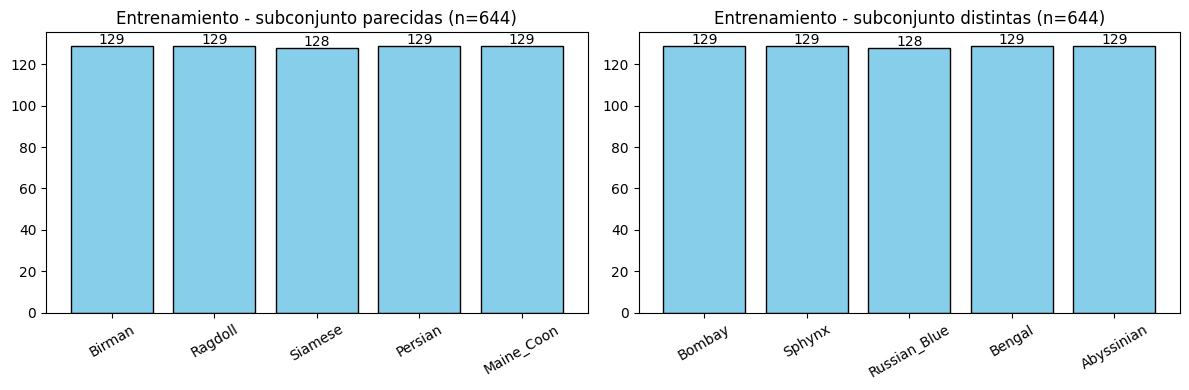

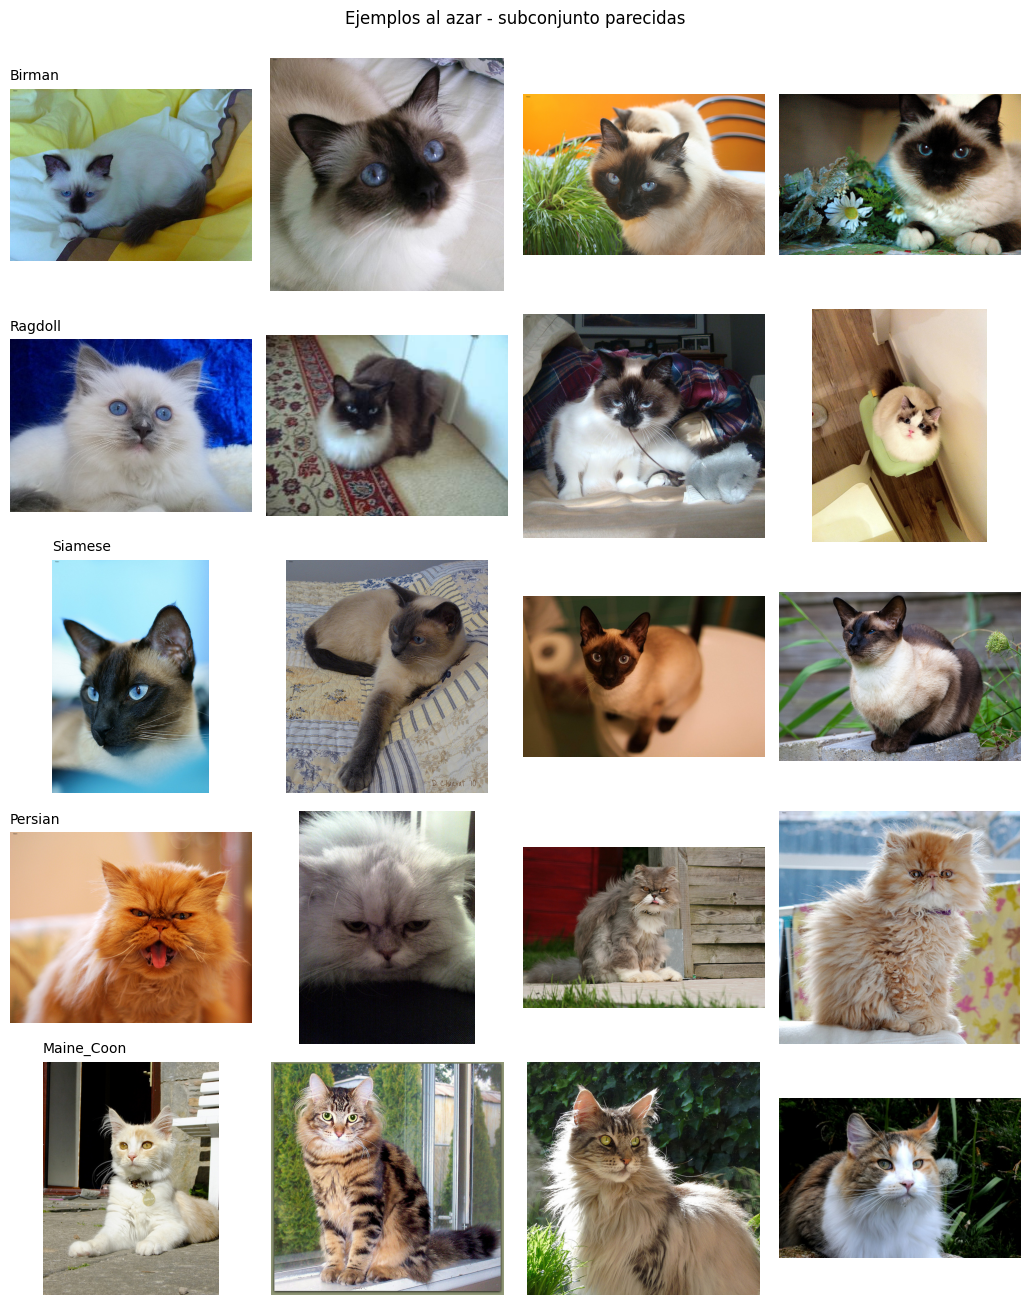

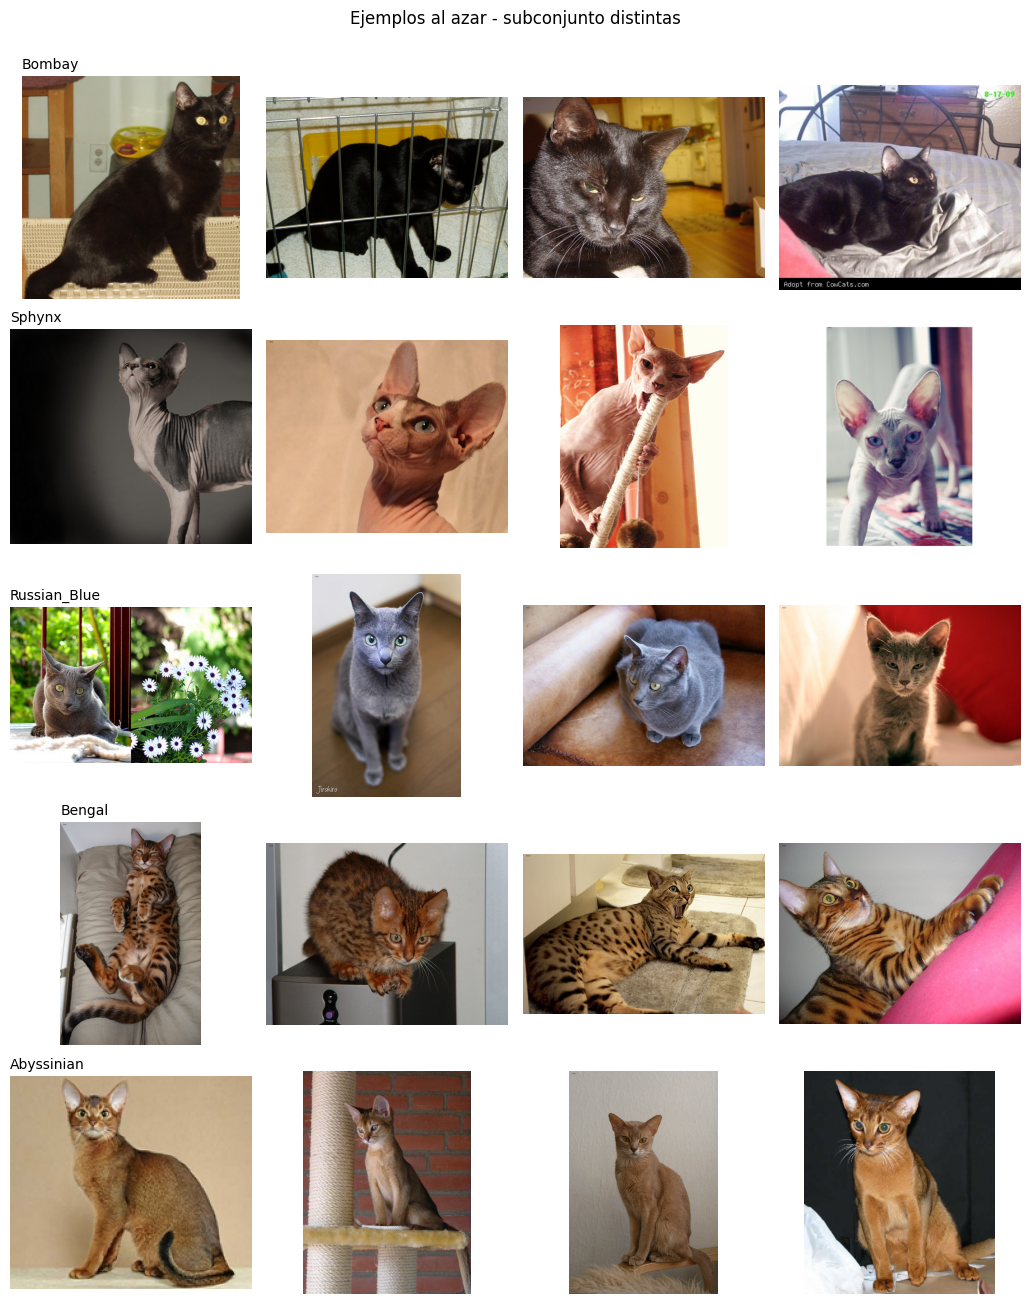

In [6]:
# ==========================================
# EDA 1: DISTRIBUCIÓN Y EJEMPLOS POR RAZA
# ==========================================
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (nombre, sp) in zip(ejes, SPLITS.items()):
    cuentas = sp["train"]["raza"].value_counts().reindex(sp["clases"])
    ax.bar(cuentas.index, cuentas.values, color="skyblue", edgecolor="black")
    ax.set_title(f"Entrenamiento - subconjunto {nombre} (n={len(sp['train'])})")
    ax.tick_params(axis="x", rotation=30)
    for i, v in enumerate(cuentas.values):
        ax.text(i, v + 1, str(v), ha="center")
plt.tight_layout(); guardar_fig("01_distribucion_clases"); plt.show()

def mostrar_ejemplos(nombre, por_raza=4):
    sp = SPLITS[nombre]; clases = sp["clases"]
    rng = np.random.default_rng(SEED_SPLIT)
    fig, ejes = plt.subplots(len(clases), por_raza, figsize=(2.6 * por_raza, 2.6 * len(clases)))
    for i, c in enumerate(clases):
        rutas = sp["train"].loc[sp["train"]["raza"] == c, "ruta"].values
        for j, r in enumerate(rng.choice(rutas, por_raza, replace=False)):
            ejes[i, j].imshow(Image.open(r).convert("RGB")); ejes[i, j].axis("off")
            if j == 0:
                ejes[i, j].set_title(c, fontsize=10, loc="left")
    plt.suptitle(f"Ejemplos al azar - subconjunto {nombre}", y=1.0)
    plt.tight_layout(); guardar_fig(f"02_ejemplos_{nombre}"); plt.show()

mostrar_ejemplos("parecidas")
mostrar_ejemplos("distintas")

Imágenes analizadas: 1288
Ancho: min 114 | max 1725 | media 438 | mediana 500
Alto:  min 108 | max 1600 | media 392 | mediana 375
Modos de color: {'RGB': 1287, 'RGBA': 1}
Imágenes corruptas: 0


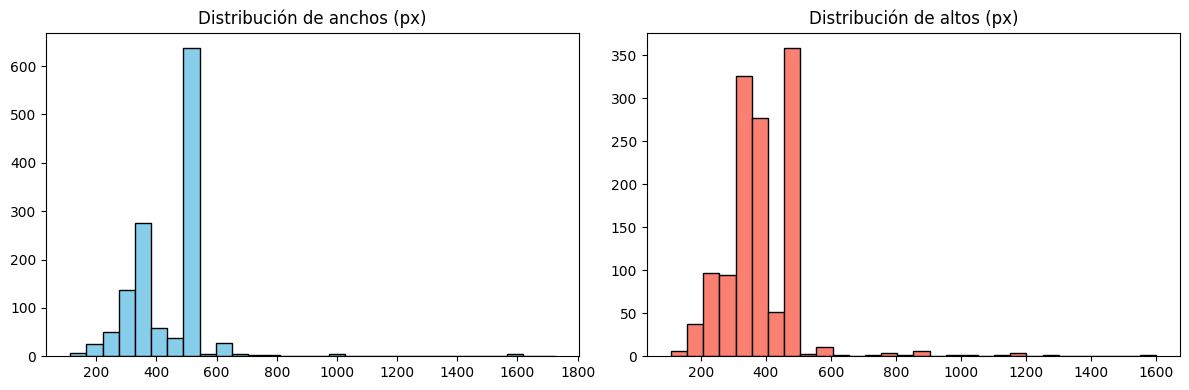

In [7]:
# ==========================================
# EDA 2: CALIDAD DE DATOS Y DIMENSIONES (100% del set de entrenamiento de ambos subconjuntos)
# ==========================================
anchos, altos, modos, corruptas = [], [], [], []
for nombre, sp in SPLITS.items():
    for r in sp["train"]["ruta"]:
        try:
            with Image.open(r) as im:
                im.load()                       # fuerza la lectura completa: detecta archivos dañados
                anchos.append(im.size[0]); altos.append(im.size[1]); modos.append(im.mode)
        except Exception as e:
            corruptas.append((r, str(e)))

print(f"Imágenes analizadas: {len(anchos)}")
print(f"Ancho: min {min(anchos)} | max {max(anchos)} | media {np.mean(anchos):.0f} | mediana {np.median(anchos):.0f}")
print(f"Alto:  min {min(altos)} | max {max(altos)} | media {np.mean(altos):.0f} | mediana {np.median(altos):.0f}")
print(f"Modos de color: {dict(Counter(modos))}")
print(f"Imágenes corruptas: {len(corruptas)}")

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].hist(anchos, bins=30, color="skyblue", edgecolor="black"); ejes[0].set_title("Distribución de anchos (px)")
ejes[1].hist(altos, bins=30, color="salmon", edgecolor="black"); ejes[1].set_title("Distribución de altos (px)")
plt.tight_layout(); guardar_fig("03_dimensiones"); plt.show()

### Interpretación del EDA

**Balance de clases.** Cada subconjunto tiene 644 imágenes de entrenamiento, con 128 o 129 por raza (Siamese y Russian_Blue tienen 128 y el resto 129). Como el muestreo tomó la misma cantidad por raza y la división fue estratificada, cada raza representa cerca del 20% del conjunto, que coincide con la línea base del azar (accuracy de 0,20). Por eso no se aplicó `class_weight` ni otro tratamiento de desbalance: las clases ya están parejas por diseño.

**Dimensiones.** Se analizaron las 1.288 imágenes de entrenamiento de ambos subconjuntos. Los anchos van de 114 a 1.725 px (media 438, mediana 500) y los altos de 108 a 1.600 px (media 392, mediana 375). Los histogramas muestran que aproximadamente la mitad de las imágenes mide cerca de 500 px de ancho y que los altos se concentran entre 300 y 500 px, con una cola de imágenes más pequeñas y unas pocas de más de 1.000 px. Como la media es menor que la mediana en el ancho, esa cola de imágenes pequeñas es la que tira el promedio hacia abajo. Las imágenes no son cuadradas (la mediana es 500x375, una proporción de 4:3), por lo que redimensionarlas a 64x64 las comprime horizontalmente en torno a un 25%. Esta deformación afecta a todas las imágenes por igual, y se acepta porque el MLP necesita una entrada de tamaño fijo.

**Calidad de datos.** No hay imágenes corruptas (0 de 1.288). Todas están en modo RGB salvo una en modo RGBA (con canal de transparencia), que `load_img` convierte a RGB al cargarla, por lo que no requiere tratamiento manual.

**Observaciones visuales (4 ejemplos al azar por raza; son impresiones, no conclusiones).**
- *PARECIDAS:* Birman, Ragdoll y Siamese comparten el patrón colorpoint (cuerpo claro con cara, orejas y patas oscuras) y, en varias fotos, ojos azules, por lo que a simple vista son difíciles de separar. Persian y Maine_Coon, en cambio, muestran mucha variación de color dentro de la misma raza (naranja, gris, blanco y, en Maine_Coon, también atigrado y calicó), así que el pelaje largo es su rasgo común y no el color. Este parecido es más débil que el del trío colorpoint: Persian y Maine_Coon difieren en la forma de la cara, el tamaño y el patrón del pelaje, por lo que PARECIDAS es un grupo relativamente parecido y no homogéneo.
- *DISTINTAS:* cada raza tiene un rasgo visual distintivo: Bombay es negro liso, Sphynx no tiene pelo, Russian_Blue es gris liso, Bengal tiene manchas y Abyssinian es de pelo corto rojizo. La excepción es que Bengal y Abyssinian comparten tonos marrón-anaranjados, y a 64x64 las manchas del Bengal podrían perderse.
- *Dificultades para ambos subconjuntos:* poses muy variadas (acostados, de espalda, sentados, estirados), fondos con mucho contenido (alfombras, plantas, jaulas, muebles), iluminación distinta, y animales que ocupan una parte pequeña de la imagen en algunas fotos. Además, una de las imágenes de Bombay tiene texto superpuesto y una de Russian_Blue parece estar compuesta por dos fotos. Con tan pocos ejemplos no se puede saber qué tan frecuentes son estos casos.
- *Hipótesis para el modelado:* si el MLP se apoya sobre todo en color y textura global, debería rendir mejor en DISTINTAS que en PARECIDAS, y en PARECIDAS debería confundir sobre todo Birman, Ragdoll y Siamese. Esto se comprueba con los resultados y no se da por supuesto.

## 4. Preprocesamiento (IE2)
Cada etapa y su justificación:
1. **Carga en RGB (3 canales):** load_img convierte a RGB la única imagen con canal alfa (RGBA) del set de entrenamiento, ya que el MLP espera una entrada de forma fija (64, 64, 3).
2. **Redimensionamiento a 64x64:** un MLP necesita un vector de entrada de tamaño fijo (64·64·3 = 12.288 valores) y las imágenes originales tienen tamaños muy distintos. Se eligió 64x64 para limitar el costo: cada píxel adicional agrega pesos a la primera capa y hay pocas imágenes de entrenamiento. El redimensionamiento deforma levemente las imágenes (no son cuadradas); se acepta porque afecta a todas por igual. 64x64 es el punto de partida; la sección 6.3 lo compara con 96x96 y 128x128 y se mantiene porque no fue superado (F1 de validación 0,397 contra 0,376 y 0,341).
3. **Normalización a [0, 1]** con una capa `Rescaling(1/255)` dentro del modelo: ayuda a que el entrenamiento sea más estable (la sección 6 muestra que estandarizar además por canal mejora aún más el resultado) y, al ser parte del modelo, se aplica igual a entrenamiento, validación y prueba, y queda guardada con él.
4. **Aumento de datos solo en entrenamiento** (volteo horizontal, rotación de hasta ~20° y desplazamientos de hasta 10%), como capas del modelo que solo actúan al entrenar. Simulan variaciones reales de cómo se fotografía un gato (cámara ladeada, animal descentrado). No se usa volteo vertical porque un gato cabeza abajo no es una situación realista.
5. **Estandarización por canal (opcional):** se prueba como experimento. Si se usa, la media y la desviación se calculan **solo con el set de entrenamiento**.

Las imágenes se cargan **una sola vez** como arreglos de NumPy (son pequeñas), lo que acelera el entrenamiento y permite repetir cada experimento con varias semillas.

In [8]:
# ==========================================
# CARGA DE IMÁGENES COMO ARREGLOS (64x64, 96x96 y 128x128)
# ==========================================
RESOLUCIONES = [64, 96, 128]      # 64 = referencia; 96 y 128 solo se usan en el experimento de la sección 6.3

def cargar(df, lado):
    return np.stack([np.array(tf.keras.utils.load_img(r, target_size=(lado, lado))) for r in df["ruta"]]).astype("float32")

for nombre, sp in SPLITS.items():
    sp["XR"] = {lado: {parte: cargar(sp[parte], lado) for parte in ["train", "val", "test"]} for lado in RESOLUCIONES}
    for parte in ["train", "val", "test"]:
        sp["y_" + parte] = sp[parte]["y"].values
        sp["X_" + parte] = sp["XR"][RES_BASE][parte]      # arreglos "por defecto" (resolución de referencia)
    formas = " | ".join(f"{lado}px: {sp['XR'][lado]['train'].shape}" for lado in RESOLUCIONES)
    print(f"{nombre:10s} X_train -> {formas}")
    print(f"{'':10s} val {sp['X_val'].shape[0]} | test {sp['X_test'].shape[0]} | rango [{sp['X_train'].min():.0f}, {sp['X_train'].max():.0f}]")

parecidas  X_train -> 64px: (644, 64, 64, 3) | 96px: (644, 96, 96, 3) | 128px: (644, 128, 128, 3)
           val 138 | test 138 | rango [0, 255]
distintas  X_train -> 64px: (644, 64, 64, 3) | 96px: (644, 96, 96, 3) | 128px: (644, 128, 128, 3)
           val 138 | test 138 | rango [0, 255]


**Resultado del preprocesamiento.** Las 920 imágenes de cada subconjunto quedaron como arreglos de forma (64, 64, 3): 644 para entrenamiento y 138 para validación y para prueba. Los valores de píxel van de 0 a 255 en esta etapa, y la normalización a [0, 1] la aplica la capa `Rescaling` dentro del modelo.
Además se cargan las mismas imágenes a 96x96 y 128x128, que solo se usan en el experimento de resolución de la sección 6.3.

In [9]:
# ==========================================
# ¿PARECIDAS ES REALMENTE MÁS PARECIDO? (solo set de entrenamiento, antes de entrenar ningún modelo)
# Dos medidas simples entre pares de razas:
#  1) distancia entre histogramas de color promedio (0 = idénticos, 1 = totalmente distintos)
#  2) distancia RMS entre las imágenes promedio de cada raza (píxel a píxel, valores en [0, 1])
# ==========================================
def hist_medio(X, bins=16):
    H = np.stack([np.concatenate([np.histogram(x[..., c], bins=bins, range=(0, 255))[0] for c in range(3)])
                  for x in X]).astype(float)
    return (H / H.sum(axis=1, keepdims=True)).mean(axis=0)

def similitud_clases(sp):
    clases, X, y = sp["clases"], sp["X_train"], sp["y_train"]
    H = [hist_medio(X[y == i]) for i in range(len(clases))]
    M = [X[y == i].mean(axis=0).ravel() / 255 for i in range(len(clases))]
    filas = []
    for i in range(len(clases)):
        for j in range(i + 1, len(clases)):
            filas.append(dict(par=f"{clases[i]} - {clases[j]}",
                              dist_histograma=0.5 * np.abs(H[i] - H[j]).sum(),
                              dist_imagen_promedio=np.sqrt(np.mean((M[i] - M[j]) ** 2))))
    return pd.DataFrame(filas)

sim = {nombre: similitud_clases(sp) for nombre, sp in SPLITS.items()}
resumen = pd.DataFrame({nombre: d[["dist_histograma", "dist_imagen_promedio"]].mean() for nombre, d in sim.items()})
print("Distancia promedio entre pares de razas (más baja = más parecidas):")
print(resumen.round(4).to_string())
for medida in ["dist_histograma", "dist_imagen_promedio"]:
    d_par, d_dis = sim["parecidas"][medida].mean(), sim["distintas"][medida].mean()
    print(f"- Según {medida}: el subconjunto más parecido es '{'parecidas' if d_par < d_dis else 'distintas'}' "
          f"(parecidas={d_par:.4f} | distintas={d_dis:.4f})")
for nombre in SPLITS:
    fila = sim[nombre].sort_values("dist_histograma").iloc[0]
    print(f"Par más parecido en '{nombre}' (histograma): {fila['par']} ({fila['dist_histograma']:.4f})")
resumen.to_csv("resultados/similitud_subconjuntos.csv")

Distancia promedio entre pares de razas (más baja = más parecidas):
                      parecidas  distintas
dist_histograma          0.0854     0.1178
dist_imagen_promedio     0.0631     0.0830
- Según dist_histograma: el subconjunto más parecido es 'parecidas' (parecidas=0.0854 | distintas=0.1178)
- Según dist_imagen_promedio: el subconjunto más parecido es 'parecidas' (parecidas=0.0631 | distintas=0.0830)
Par más parecido en 'parecidas' (histograma): Birman - Siamese (0.0404)
Par más parecido en 'distintas' (histograma): Bengal - Abyssinian (0.0743)


### Interpretación de la similitud entre razas

Antes de entrenar cualquier modelo, se midió la distancia entre pares de razas en el set de entrenamiento con dos indicadores (a menor valor, más parecidas):

| Medida (promedio de los 10 pares de razas) | PARECIDAS | DISTINTAS |
|---|---|---|
| Distancia entre histogramas de color | 0,0854 | 0,1178 |
| Distancia entre imágenes promedio | 0,0631 | 0,0830 |

Con ambas medidas, PARECIDAS tiene distancias menores: unos 27% menos en el histograma de color y unos 24% menos en la imagen promedio. Esto respalda con datos el criterio con que se armaron los subconjuntos. Además, el par más parecido de PARECIDAS (Birman - Siamese, 0,0404) está casi a la mitad de distancia que el par más parecido de DISTINTAS (Bengal - Abyssinian, 0,0743). Birman y Siamese comparten el patrón colorpoint, y Bengal y Abyssinian son los dos gatos marrón-anaranjados de DISTINTAS, algo que ya se notaba en los ejemplos del EDA.

**Alcance y limitaciones.** La diferencia es moderada, no enorme: DISTINTAS no es un conjunto de razas "opuestas", sino uno donde las razas son algo más distinguibles. Ambas medidas capturan solo color y apariencia global, no forma local (orejas, hocico, contorno del cuerpo), por lo que son un indicador parcial del parecido visual. Con 10 pares por subconjunto y una sola medida de cada tipo, tampoco se puede afirmar que todos los pares de PARECIDAS sean más cercanos que todos los de DISTINTAS, solo que el promedio lo es. Por último, como esta medición se hizo antes de entrenar cualquier modelo, no hubo necesidad de ajustar la selección de razas.

**Hipótesis para el modelado:** si el MLP se apoya principalmente en color y textura global, debería rendir mejor en DISTINTAS que en PARECIDAS, y en PARECIDAS debería confundir sobre todo Birman con Siamese.

## 5. Diseño del Perceptrón Multicapa (IE3)
Se parte de un MLP **base**, con la arquitectura más simple razonable, para medir hasta dónde llega una red densa sobre píxeles aplanados. Cada decisión se justifica por las características del problema (5 clases, imágenes a color de 64x64, 644 imágenes de entrenamiento):

| Componente | Valor base | Justificación |
|---|---|---|
| **Entrada** | `Flatten` sobre (64, 64, 3) → 12.288 valores | Un MLP solo acepta vectores 1D. Aplanar descarta la vecindad entre píxeles (limitación que se analiza en la sección 11). |
| **Capas ocultas** | 1 | Modelo base. Con 644 imágenes, una red más profunda aumenta el riesgo de memorizar. Se compara con 2 capas en los experimentos. |
| **Neuronas** | 128 | Tamaño intermedio: suficiente para combinar los 12.288 valores en patrones, sin que los parámetros se disparen (cada neurona agrega 12.288 pesos). Se comparan 64 y 256. |
| **Activación oculta** | ReLU | No se satura para valores positivos, por lo que mitiga el desvanecimiento del gradiente que afecta a sigmoide y tanh; además es barata de calcular. Se comparan LeakyReLU y tanh. |
| **Regularización** | Dropout 0,3 + aumento de datos | La primera capa tiene más de 1,5 millones de pesos para 644 imágenes: hay riesgo de memorización. Se compara también sin dropout. Ojo: el diagnóstico final no fue de sobreajuste sino de aprendizaje limitado (sección 7). La ronda 2 reevaluó la regularización sobre una base que sí aprende (B5 dropout 0, B6 dropout 0,5 y B9 sin aumento de datos): quitar el dropout o el aumento sube el sobreajuste, por eso se mantienen.|
| **Salida** | `Dense(5)` con **softmax** | Hay 5 clases excluyentes: softmax entrega una distribución de probabilidad que suma 1 sobre las 5 razas, y la clase predicha es la de mayor probabilidad. |
| **Pérdida** | `sparse_categorical_crossentropy` | Es la pérdida estándar para salida softmax; "sparse" porque las etiquetas son enteros (0 a 4) y no vectores one-hot. Penaliza fuertemente asignar baja probabilidad a la raza correcta. |
| **Optimizador** | Adam, learning rate 0,001 | Adapta el paso de cada peso por separado. 0,001 es su valor por defecto y se toma como punto de partida, no como valor definitivo: el learning rate se explora (3e-4 y 1e-4). La sección 6 mostró que sí importa: con 1e-4 el F1 macro de validación pasó de 0,134 a 0,352. |
| **Batch size** | 32 | Con 644 imágenes son ~20 actualizaciones por época: estable y liviano. Se comparan 16 y 64. Con 644 imágenes, batch 16 daría unas 40 actualizaciones por época con gradientes más ruidosos, y batch 64 solo unas 10; 32 es un punto intermedio. |
| **Épocas** | Máximo 150 + `EarlyStopping` sobre `val_loss` (paciencia 7 como base y 20 en la configuración final; restaura los mejores pesos) | El número de épocas no se fija a ojo: se detiene cuando la pérdida de validación deja de mejorar. **Paciencia:** la base usa 7 (con ~20 actualizaciones por época son unas 140 sin mejora antes de parar) y la sección 6.2 compara con 20, porque con solo 138 imágenes la pérdida de validación oscila y una paciencia corta podría cortar un modelo que aprende lento. **Máximo 150:** deja margen sobre las mejores épocas observadas en la sección 6, que informa cuántas corridas llegan al tope (0 de 39 en la ronda 1; 1 en la ronda 2). **Por qué `val_loss` y no el accuracy:** con solo 138 imágenes el accuracy de validación del modelo final oscila entre 0,304 y 0,435 de una época a otra (sección 7), mientras que la pérdida se mueve en un rango más acotado después de las primeras épocas, por lo que es una señal más confiable para decidir cuándo parar. **Restaurar los mejores pesos:** evita quedarse con los de las últimas épocas, que ya no mejoraron. |
| **Línea base** | Azar = 1/5 = 20% | Con clases balanceadas, un modelo sin información acierta ~20%. |

In [10]:
# ==========================================
# FUNCIONES DEL MODELO, ENTRENAMIENTO Y MÉTRICAS
# ==========================================
def crear_mlp(n_clases, neuronas=128, capas=1, activacion="relu", dropout=0.3, lr=1e-3,
              aumento=True, estandarizar=False, X_adapt=None, resolucion=RES_BASE):
    lista_capas = [layers.Input(shape=(resolucion, resolucion, 3))]
    if aumento:   # solo actúan durante el entrenamiento
        lista_capas += [layers.RandomFlip("horizontal"), layers.RandomRotation(0.055), layers.RandomTranslation(0.1, 0.1)]
    lista_capas.append(layers.Rescaling(1 / 255))
    if estandarizar:
        norm = layers.Normalization(axis=-1)
        norm.adapt(X_adapt / 255.0)            # media y desviación calculadas SOLO con entrenamiento
        lista_capas.append(norm)
    lista_capas.append(layers.Flatten())
    for _ in range(capas):
        lista_capas.append(layers.Dense(neuronas))
        lista_capas.append(layers.LeakyReLU(negative_slope=0.01) if activacion == "leaky_relu" else layers.Activation(activacion))
        lista_capas.append(layers.Dropout(dropout))
    lista_capas.append(layers.Dense(n_clases, activation="softmax"))
    m = models.Sequential(lista_capas)
    m.compile(optimizer=optimizers.Adam(learning_rate=lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def entrenar(sp, seed, **cfg):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    cfg = dict(cfg)
    batch = cfg.pop("batch", BATCH_SIZE)
    pac = cfg.pop("paciencia", PACIENCIA)
    D = sp["XR"][cfg.get("resolucion", RES_BASE)]      # 'resolucion' se queda en cfg: crear_mlp la usa para la entrada
    m = crear_mlp(len(sp["clases"]), X_adapt=D["train"], **cfg)
    es = EarlyStopping(monitor="val_loss", patience=pac, restore_best_weights=True)
    h = m.fit(D["train"], sp["y_train"], validation_data=(D["val"], sp["y_val"]),
              epochs=EPOCAS_MAX, batch_size=batch, callbacks=[es], verbose=0)
    return m, h

def metricas(m, X, y):
    pred = m.predict(X, verbose=0).argmax(axis=1)
    return dict(acc=accuracy_score(y, pred),
                f1=f1_score(y, pred, average="macro", zero_division=0),
                recall_min=recall_score(y, pred, average=None, zero_division=0).min()), pred

crear_mlp(5).summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 64, 64, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 64, 64, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,572,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,573,637 (6.00 MB)

 Trainable params: 1,573,637 (6.00 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# ==========================================
# VERIFICACIÓN DE REPRODUCIBILIDAD: dos entrenamientos con la misma semilla deben dar resultados idénticos
# ==========================================
def prueba_determinismo(semilla=11, epocas=3):
    sp = SPLITS["parecidas"]; D = sp["XR"][RES_BASE]; perdidas = []
    for _ in range(2):
        tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(semilla)
        m = crear_mlp(len(sp["clases"]), X_adapt=D["train"], lr=1e-4, estandarizar=True)
        h = m.fit(D["train"], sp["y_train"], validation_data=(D["val"], sp["y_val"]),
                  epochs=epocas, batch_size=BATCH_SIZE, verbose=0)
        perdidas.append(h.history["val_loss"])
    return perdidas

p1, p2 = prueba_determinismo()
print("Pérdida de validación, corrida 1:", [round(v, 6) for v in p1])
print("Pérdida de validación, corrida 2:", [round(v, 6) for v in p2])
if p1 == p2:
    print("REPRODUCIBLE: los dos entrenamientos con la misma semilla son idénticos.")
else:
    print("NO REPRODUCIBLE: los entrenamientos difieren. Cambia el entorno a CPU "
          "(Entorno de ejecución > Cambiar tipo de entorno > CPU) y vuelve a ejecutar todo.")

Pérdida de validación, corrida 1: [1.862238, 1.70207, 1.832503]
Pérdida de validación, corrida 2: [1.862238, 1.70207, 1.832503]
REPRODUCIBLE: los dos entrenamientos con la misma semilla son idénticos.


## 6. Experimentación y selección del modelo (IE3, IE4)
**Diseño:** se parte del modelo base **M0** y se cambia **un factor a la vez** (aumento de datos, learning rate, neuronas, profundidad, activación, batch size, estandarización y dropout). Cada configuración se entrena con **3 semillas de inicialización** y se reporta media ± desviación estándar, porque con 138 imágenes de validación una sola ejecución es muy ruidosa. Todo se hace sobre el subconjunto **PARECIDAS** y **se evalúa en validación; en esta sección el set de prueba no se usa para comparar configuraciones** (ver la salvedad de transparencia en 6.2)

La sección tiene tres partes: **6.1 Ronda 1** (13 configuraciones sobre M0), **6.2 Ronda 2** (parte de lo aprendido en la ronda 1 y repite los factores que habían quedado sin medir bien) y **6.3 Resolución de entrada** (64x64, 96x96 y 128x128).

**Criterio de selección (definido antes de ejecutar, igual en las tres partes):** se elige la configuración con **mayor F1 macro de validación promedio**. Si otras configuraciones quedan dentro de **una desviación estándar** de la mejor, se prefiere la de **menos parámetros** (la más simple), porque diferencias menores que el ruido no justifican más complejidad. Si dos empatan en parámetros, gana la de mayor F1.

**Limitación del diseño:** cambiar un factor a la vez no explora interacciones entre factores (por ejemplo, el mejor learning rate podría depender del número de neuronas).

*Tiempo estimado: unos 87 entrenamientos en total (ronda 1: 13 configuraciones x 3 semillas; ronda 2: 13 x 3, reutilizando la base; resolución: 3 x 3). Los segundos por corrida se registran desde la ronda 2 (columna `segundos`); la ronda 1 no los registró. En conjunto pueden ser varias decenas de minutos en GPU y bastante más en CPU.*

In [12]:
# ==========================================
# EJECUCIÓN DE LOS EXPERIMENTOS (sobre PARECIDAS, métricas en VALIDACIÓN)
# ==========================================
BASE = dict(neuronas=128, capas=1, activacion="relu", dropout=0.3, lr=1e-3, aumento=True, estandarizar=False, batch=32)
CONFIGS = {
    "M0 base": {},
    "M1 sin aumento de datos": dict(aumento=False),
    "M2 lr 3e-4": dict(lr=3e-4),
    "M3 lr 1e-4": dict(lr=1e-4),
    "M4 64 neuronas": dict(neuronas=64),
    "M5 256 neuronas": dict(neuronas=256),
    "M6 2 capas ocultas": dict(capas=2),
    "M7 LeakyReLU": dict(activacion="leaky_relu"),
    "M8 tanh": dict(activacion="tanh"),
    "M9 batch 16": dict(batch=16),
    "M10 batch 64": dict(batch=64),
    "M11 estandarización": dict(estandarizar=True),
    "M12 sin dropout": dict(dropout=0.0),
}

sp = SPLITS["parecidas"]
filas = []
for nombre, cambios in CONFIGS.items():
    cfg = {**BASE, **cambios}
    for s in SEEDS_EXP:
        m, h = entrenar(sp, s, **cfg)
        met, _ = metricas(m, sp["X_val"], sp["y_val"])
        mejor_ep = int(np.argmin(h.history["val_loss"]))
        filas.append(dict(config=nombre, semilla=s, parametros=m.count_params(),
                          epoca_mejor=mejor_ep + 1, epocas_totales=len(h.history["loss"]),
                          acc_train=h.history["accuracy"][mejor_ep], acc_val=met["acc"], f1_val=met["f1"],
                          val_loss=min(h.history["val_loss"])))
    print(f"{nombre}: listo")
runs = pd.DataFrame(filas)
runs.to_csv("resultados/experimentos_parecidas_por_semilla.csv", index=False)

M0 base: listo
M1 sin aumento de datos: listo
M2 lr 3e-4: listo
M3 lr 1e-4: listo
M4 64 neuronas: listo
M5 256 neuronas: listo
M6 2 capas ocultas: listo
M7 LeakyReLU: listo
M8 tanh: listo
M9 batch 16: listo
M10 batch 64: listo
M11 estandarización: listo
M12 sin dropout: listo


| config                  |   parametros |   epoca_mejor |   acc_train |   acc_val_media |   acc_val_std |   f1_val_media |   f1_val_std |
|:------------------------|-------------:|--------------:|------------:|----------------:|--------------:|---------------:|-------------:|
| M0 base                 |      1573637 |         8.333 |       0.219 |           0.229 |         0.008 |          0.134 |        0.009 |
| M1 sin aumento de datos |      1573637 |         4.667 |       0.220 |           0.249 |         0.041 |          0.132 |        0.057 |
| M2 lr 3e-4              |      1573637 |         4.000 |       0.224 |           0.225 |         0.019 |          0.131 |        0.044 |
| M3 lr 1e-4              |      1573637 |        39.333 |       0.316 |           0.362 |         0.007 |          0.352 |        0.006 |
| M4 64 neuronas          |       786821 |         1.667 |       0.197 |           0.229 |         0.027 |          0.126 |        0.042 |
| M5 256 neuronas         |

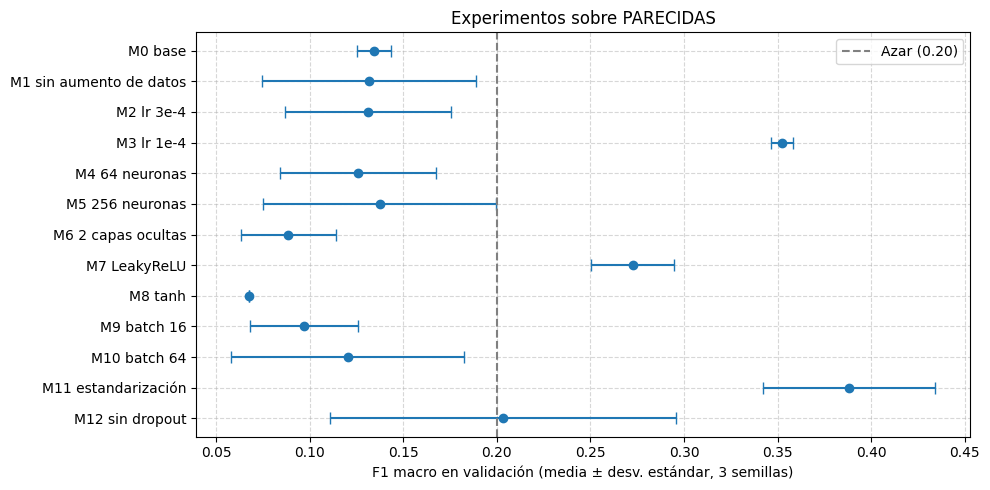


Mejor F1 macro de validación: M11 estandarización (0.388 ± 0.046)
Configuraciones dentro de 1 desv. estándar de la mejor: ['M3 lr 1e-4', 'M11 estandarización']
==> CONFIGURACIÓN DE LA RONDA 1: M3 lr 1e-4
{'neuronas': 128, 'capas': 1, 'activacion': 'relu', 'dropout': 0.3, 'lr': 0.0001, 'aumento': True, 'estandarizar': False, 'batch': 32}


In [13]:
# ==========================================
# TABLA COMPARATIVA, GRÁFICO Y SELECCIÓN (criterio definido arriba)
# ==========================================
res = (runs.groupby("config", sort=False)
       .agg(parametros=("parametros", "first"), epoca_mejor=("epoca_mejor", "mean"),
            acc_train=("acc_train", "mean"), acc_val_media=("acc_val", "mean"), acc_val_std=("acc_val", "std"),
            f1_val_media=("f1_val", "mean"), f1_val_std=("f1_val", "std")).reset_index())
print(res.to_markdown(index=False, floatfmt=".3f"))
res.to_csv("resultados/experimentos_parecidas_resumen.csv", index=False)
print(f"\nCorridas que llegaron al tope de {EPOCAS_MAX} épocas: {int((runs['epocas_totales'] >= EPOCAS_MAX).sum())} de {len(runs)}")

azar = 1 / len(SPLITS["parecidas"]["clases"])
plt.figure(figsize=(10, 5))
plt.errorbar(res["f1_val_media"], range(len(res)), xerr=res["f1_val_std"], fmt="o", capsize=4)
plt.yticks(range(len(res)), res["config"]); plt.gca().invert_yaxis()
plt.axvline(azar, color="gray", linestyle="--", label=f"Azar ({azar:.2f})")
plt.xlabel("F1 macro en validación (media ± desv. estándar, 3 semillas)")
plt.title("Experimentos sobre PARECIDAS"); plt.legend(); plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout(); guardar_fig("04_experimentos_f1_validacion"); plt.show()

# --- Selección según el criterio (si hay empate en parámetros, gana la de mayor F1) ---
mejor = res.sort_values("f1_val_media", ascending=False).iloc[0]
candidatas = res[res["f1_val_media"] >= mejor["f1_val_media"] - mejor["f1_val_std"]]
elegida = candidatas.sort_values(["parametros", "f1_val_media"], ascending=[True, False]).iloc[0]["config"]
CFG_REF = {**BASE, **CONFIGS[elegida]}
CFG_R1 = dict(CFG_REF)     # configuración elegida en la ronda 1 (se usa en la comparación final de la sección 8)
print(f"\nMejor F1 macro de validación: {mejor['config']} ({mejor['f1_val_media']:.3f} ± {mejor['f1_val_std']:.3f})")
print(f"Configuraciones dentro de 1 desv. estándar de la mejor: {list(candidatas['config'])}")
print(f"==> CONFIGURACIÓN DE LA RONDA 1: {elegida}")
print(CFG_R1)

### Interpretación de los experimentos (ronda 1)
**¿Qué supera el ruido?** El modelo base M0 obtuvo F1 macro de validación **0,134 ± 0,009** y accuracy 0,229, apenas sobre el azar (0,20). Solo tres cambios se separan de M0 por más que su desviación estándar: **M11 estandarización (0,388 ± 0,046)**, **M3 learning rate 1e-4 (0,352 ± 0,006)** y **M7 LeakyReLU (0,273 ± 0,022)**. El resto se solapa con M0 (sin aumento 0,132 ± 0,057; lr 3e-4 0,131 ± 0,044; 64 y 256 neuronas 0,126 y 0,137; batch 16 y 64 0,097 y 0,120; sin dropout 0,203 ± 0,092) o queda por debajo: 2 capas ocultas (0,089 ± 0,025) y tanh (0,067 ± 0,000).

**Un F1 de 0,07 a 0,13 con accuracy cercano a 0,20 indica un modelo casi estancado.** Un modelo que predijera siempre la misma raza en 5 clases balanceadas tendría accuracy 0,20 y F1 macro ≈ 0,07. Tanh (accuracy 0,203, F1 0,067 y desviación 0,000 entre las 3 semillas) se comporta exactamente así. M0 tuvo su mejor época en promedio alrededor de la 8 y `EarlyStopping` lo detuvo poco después, sin que hubiera aprendido nada útil.

**Por qué ayudaron esos tres cambios (hipótesis, no se probó directamente).** Con 12.288 entradas en [0, 1] y learning rate 1e-3, el entrenamiento parece quedarse en una meseta cercana al azar. Bajar el learning rate (M3) o centrar y escalar las entradas (M11) hacen el entrenamiento más estable, y ambos aprendieron, aunque lentamente: su mejor época fue en promedio la 39 y la 49, contra la 8 de M0. LeakyReLU también mejoró (de 0,134 a 0,273), lo que podría deberse a neuronas ReLU que dejan de activarse, pero no lo verificamos. Esto muestra con datos por qué el número de épocas no puede fijarse en 20: los modelos que sí aprenden necesitan bastantes más. Ninguna corrida llegó al tope de 150 épocas (0 de 39).

**Limitación importante del diseño.** Como M0 estaba estancado, los factores que no ayudaron (neuronas, profundidad, batch, dropout, aumento) se midieron sobre un modelo que casi no aprendía, por lo que su efecto nulo **no se puede generalizar**. La sección 6.2 los repite sobre una base que sí aprende.

**Elección de la configuración de la ronda 1.** El mejor F1 de validación fue M11 (0,388 ± 0,046). Quedaron dentro de una desviación estándar M3 y M11, y el criterio fijado antes de ejecutar dice que se prefiere la de menos parámetros: **M3 (lr 1e-4)**. La diferencia de parámetros es mínima (1.573.637 contra 1.573.644, la capa de estandarización), así que el desempate fue prácticamente formal. Aun así, M3 es una elección razonable: su desviación entre semillas es la menor (0,006) y no muestra sobreajuste (accuracy de entrenamiento 0,316 y de validación 0,362), mientras que M11 sí empieza a separar entrenamiento y validación (0,463 contra 0,394).

**Comparación con el azar.** Las mejores configuraciones llegan a accuracy de validación de 0,36 a 0,39, entre 16 y 19 puntos sobre el azar de 0,20. Ninguna alcanza el F1 de 0,40 del KPI, ni siquiera en validación.

**Reproducibilidad.** Estas cifras son reproducibles: con el modo determinista activado, la celda de verificación de la sección 5 dio pérdidas idénticas en dos entrenamientos con la misma semilla.

**Limitaciones:** un factor a la vez (no se exploran interacciones), solo 3 semillas y 138 imágenes de validación.

### 6.2 Ronda 2: pendientes de la ronda 1
**Por qué una segunda ronda.** La ronda 1 dejó tres pendientes que el propio análisis reconoce:
1. Neuronas, profundidad, batch, dropout y aumento de datos se midieron sobre un M0 que casi no aprendía, así que su efecto nulo no es concluyente.
2. Las dos mejoras que sí funcionaron (learning rate 1e-4 y estandarización) no se probaron juntas.
3. El `EarlyStopping` con paciencia 7 podría estar cortando modelos lentos, porque la pérdida de validación es ruidosa (138 imágenes). Eso confundiría la explicación de por qué M0 "estaba estancado".

**Transparencia.** Esta ronda se diseñó después de ver los resultados de validación de la ronda 1 y una primera evaluación en prueba de la configuración M3 en una ejecución anterior del notebook, cuyo KPI principal no se cumplía. Por lo tanto, **la configuración final se eligió solo con validación, pero la ronda 2 se diseñó tras ver un resultado en prueba, así que la independencia del set de prueba no es total.** Para limitar el sesgo: toda selección usa solo validación, los KPIs no se modifican, y el set de prueba se evalúa con la configuración final (se muestra además la configuración de la ronda 1 para comparar, sin usarla para elegir).

**Diseño (definido antes de ejecutar).**
- **Paso A:** base M3 (learning rate 1e-4) contra M3 + estandarización, cada una con paciencia 7 y con paciencia 20 (4 configuraciones). Responde los pendientes 2 y 3.
- **Paso B:** sobre la mejor base del paso A se cambia un factor a la vez: neuronas (64 y 256), 2 capas, LeakyReLU, dropout (0 y 0,5), batch (16 y 64) y sin aumento de datos (9 configuraciones). Responde el pendiente 1.
- Mismas métricas, 3 semillas y criterio de selección de la ronda 1. Se sube `EPOCAS_MAX` a 150 y se informa cuántas corridas llegan al tope.

**Limitación.** Es una búsqueda por pasos alrededor de una base, no una grilla completa: no explora todas las interacciones.

In [14]:
# ==========================================
# FUNCIONES AUXILIARES PARA LA RONDA 2 (mismas reglas que la ronda 1)
# ==========================================
def correr_configs(configs, base, sp, semillas):
    filas = []
    for nombre, cambios in configs.items():
        cfg = {**base, **cambios}
        D = sp["XR"][cfg.get("resolucion", RES_BASE)]
        for s in semillas:
            t0 = time.time()
            m, h = entrenar(sp, s, **cfg)
            seg = time.time() - t0
            met, _ = metricas(m, D["val"], sp["y_val"])
            mejor_ep = int(np.argmin(h.history["val_loss"]))
            n_ep = len(h.history["loss"])
            filas.append(dict(config=nombre, semilla=s, parametros=m.count_params(),
                              epoca_mejor=mejor_ep + 1, epocas_totales=n_ep, llego_al_tope=n_ep >= EPOCAS_MAX,
                              segundos=seg, acc_train=h.history["accuracy"][mejor_ep], acc_val=met["acc"],
                              f1_val=met["f1"], val_loss=min(h.history["val_loss"])))
        print(f"{nombre}: listo")
    return pd.DataFrame(filas)

def resumir(runs):
    return (runs.groupby("config", sort=False)
            .agg(parametros=("parametros", "first"), epoca_mejor=("epoca_mejor", "mean"), segundos=("segundos", "mean"),
                 acc_train=("acc_train", "mean"), acc_val_media=("acc_val", "mean"), acc_val_std=("acc_val", "std"),
                 f1_val_media=("f1_val", "mean"), f1_val_std=("f1_val", "std"), topes=("llego_al_tope", "sum"))
            .reset_index())

def seleccionar(res):
    """Mayor F1 de validación; entre las que quedan a 1 desv. estándar, la de menos parámetros (si empatan, la de mayor F1)."""
    mejor = res.sort_values("f1_val_media", ascending=False).iloc[0]
    cand = res[res["f1_val_media"] >= mejor["f1_val_media"] - mejor["f1_val_std"]]
    elegida = cand.sort_values(["parametros", "f1_val_media"], ascending=[True, False]).iloc[0]["config"]
    return mejor, cand, elegida

def grafico_f1(res, titulo, archivo):
    azar = 1 / len(SPLITS["parecidas"]["clases"])
    plt.figure(figsize=(10, 0.5 * len(res) + 2))
    plt.errorbar(res["f1_val_media"], range(len(res)), xerr=res["f1_val_std"], fmt="o", capsize=4)
    plt.yticks(range(len(res)), res["config"]); plt.gca().invert_yaxis()
    plt.axvline(azar, color="gray", linestyle="--", label=f"Azar ({azar:.2f})")
    plt.xlabel("F1 macro en validación (media ± desv. estándar, 3 semillas)")
    plt.title(titulo); plt.legend(); plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout(); guardar_fig(archivo); plt.show()

A0 M3 (lr 1e-4): listo
A1 M3 + estandarización: listo
A2 M3 + paciencia 20: listo
A3 M3 + estandarización + paciencia 20: listo
| config                                 |   parametros |   epoca_mejor |   segundos |   acc_train |   acc_val_media |   acc_val_std |   f1_val_media |   f1_val_std |   topes |
|:---------------------------------------|-------------:|--------------:|-----------:|------------:|----------------:|--------------:|---------------:|-------------:|--------:|
| A0 M3 (lr 1e-4)                        |      1573637 |        39.333 |     13.079 |       0.316 |           0.362 |         0.007 |          0.352 |        0.006 |       0 |
| A1 M3 + estandarización                |      1573644 |        14.333 |      7.460 |       0.373 |           0.391 |         0.019 |          0.388 |        0.020 |       0 |
| A2 M3 + paciencia 20                   |      1573637 |        97.000 |     29.259 |       0.336 |           0.345 |         0.018 |          0.332 |        0.013

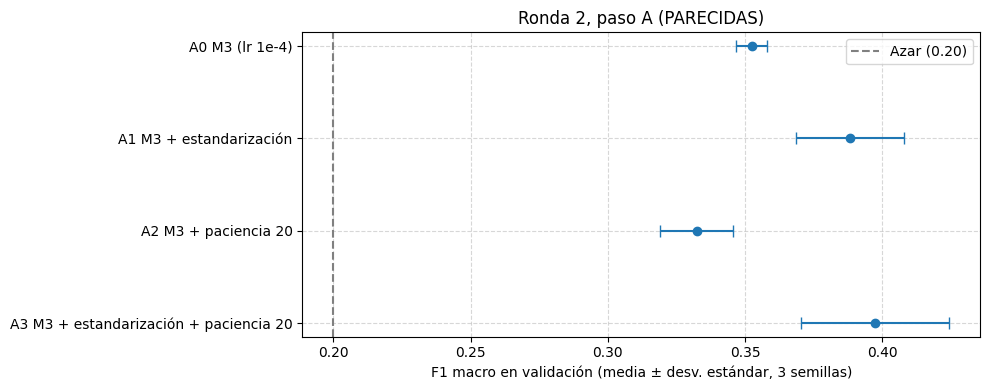


Mejor F1 macro de validación: A3 M3 + estandarización + paciencia 20 (0.397 ± 0.027)
Dentro de 1 desv. estándar de la mejor: ['A1 M3 + estandarización', 'A3 M3 + estandarización + paciencia 20']
==> BASE PARA EL PASO B: A3 M3 + estandarización + paciencia 20
{'neuronas': 128, 'capas': 1, 'activacion': 'relu', 'dropout': 0.3, 'lr': 0.0001, 'aumento': True, 'estandarizar': True, 'batch': 32, 'paciencia': 20}


In [15]:
# ==========================================
# RONDA 2 - PASO A: ¿JUNTAR LR 1e-4 + ESTANDARIZACIÓN? ¿IMPORTA LA PACIENCIA?
# (PARECIDAS, métricas en VALIDACIÓN, 3 semillas)
# ==========================================
BASE2 = {**BASE, "lr": 1e-4}
PASO_A = {
    "A0 M3 (lr 1e-4)": {},
    "A1 M3 + estandarización": dict(estandarizar=True),
    "A2 M3 + paciencia 20": dict(paciencia=20),
    "A3 M3 + estandarización + paciencia 20": dict(estandarizar=True, paciencia=20),
}
sp = SPLITS["parecidas"]
runs_A = correr_configs(PASO_A, BASE2, sp, SEEDS_EXP)
runs_A.to_csv("resultados/ronda2_paso_A_por_semilla.csv", index=False)
res_A = resumir(runs_A)
print(res_A.to_markdown(index=False, floatfmt=".3f"))
res_A.to_csv("resultados/ronda2_paso_A_resumen.csv", index=False)
grafico_f1(res_A, "Ronda 2, paso A (PARECIDAS)", "04b_ronda2_paso_A")

mejor_A, cand_A, elegida_A = seleccionar(res_A)
BASE_B = {**BASE2, **PASO_A[elegida_A]}
print(f"\nMejor F1 macro de validación: {mejor_A['config']} ({mejor_A['f1_val_media']:.3f} ± {mejor_A['f1_val_std']:.3f})")
print(f"Dentro de 1 desv. estándar de la mejor: {list(cand_A['config'])}")
print(f"==> BASE PARA EL PASO B: {elegida_A}")
print(BASE_B)

B1 64 neuronas: listo
B2 256 neuronas: listo
B3 2 capas ocultas: listo
B4 LeakyReLU: listo
B5 dropout 0: listo
B6 dropout 0,5: listo
B7 batch 16: listo
B8 batch 64: listo
B9 sin aumento de datos: listo
| config                                           |   parametros |   epoca_mejor |   segundos |   acc_train |   acc_val_media |   acc_val_std |   f1_val_media |   f1_val_std |   topes |
|:-------------------------------------------------|-------------:|--------------:|-----------:|------------:|----------------:|--------------:|---------------:|-------------:|--------:|
| B0 base (A3 M3 + estandarización + paciencia 20) |      1573644 |        46.667 |     17.983 |       0.434 |           0.396 |         0.025 |          0.397 |        0.027 |       0 |
| B1 64 neuronas                                   |       786828 |        13.000 |      9.815 |       0.365 |           0.360 |         0.029 |          0.356 |        0.029 |       0 |
| B2 256 neuronas                                 

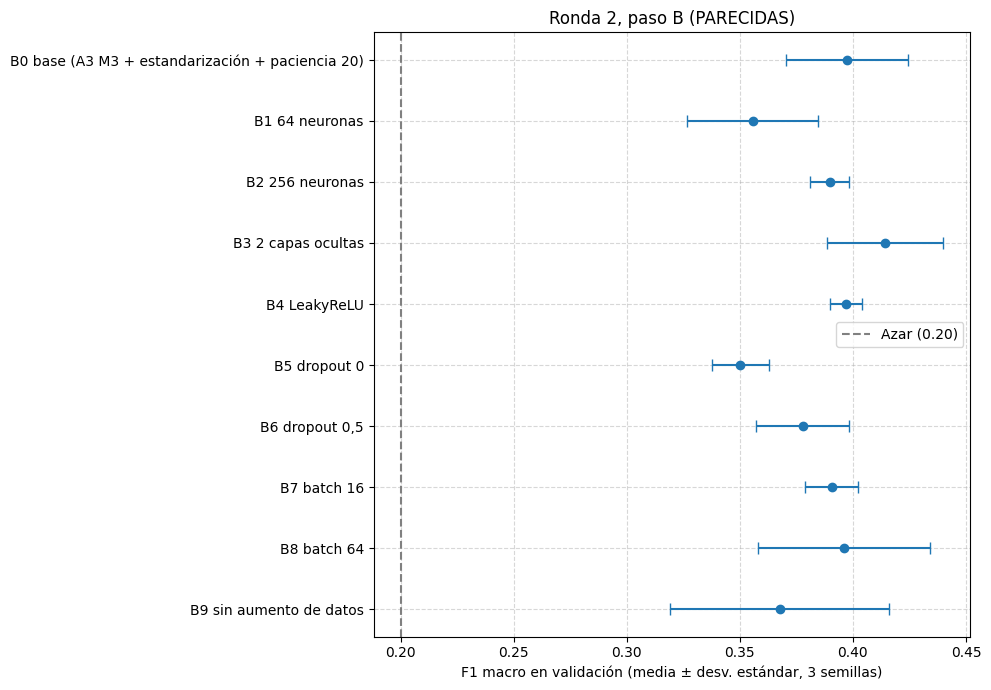


Mejor F1 macro de validación: B3 2 capas ocultas (0.414 ± 0.026)
Dentro de 1 desv. estándar de la mejor: ['B0 base (A3 M3 + estandarización + paciencia 20)', 'B2 256 neuronas', 'B3 2 capas ocultas', 'B4 LeakyReLU', 'B7 batch 16', 'B8 batch 64']
==> CONFIGURACIÓN DE LA RONDA 2: B0 base (A3 M3 + estandarización + paciencia 20)
{'neuronas': 128, 'capas': 1, 'activacion': 'relu', 'dropout': 0.3, 'lr': 0.0001, 'aumento': True, 'estandarizar': True, 'batch': 32, 'paciencia': 20}
Corridas de la ronda 2 que llegaron al tope de 150 épocas: 1


In [16]:
# ==========================================
# RONDA 2 - PASO B: UN FACTOR A LA VEZ SOBRE LA BASE ELEGIDA EN EL PASO A
# ==========================================
FACTORES_B = {
    "B1 64 neuronas": dict(neuronas=64),
    "B2 256 neuronas": dict(neuronas=256),
    "B3 2 capas ocultas": dict(capas=2),
    "B4 LeakyReLU": dict(activacion="leaky_relu"),
    "B5 dropout 0": dict(dropout=0.0),
    "B6 dropout 0,5": dict(dropout=0.5),
    "B7 batch 16": dict(batch=16),
    "B8 batch 64": dict(batch=64),
    "B9 sin aumento de datos": dict(aumento=False),
}
runs_B = correr_configs(FACTORES_B, BASE_B, sp, SEEDS_EXP)

# La base del paso B es la configuración ganadora del paso A: se reutilizan sus corridas (mismas semillas)
nombre_base = f"B0 base ({elegida_A})"
runs_B = pd.concat([runs_A[runs_A["config"] == elegida_A].assign(config=nombre_base), runs_B], ignore_index=True)
runs_B.to_csv("resultados/ronda2_paso_B_por_semilla.csv", index=False)
res_B = resumir(runs_B)
print(res_B.to_markdown(index=False, floatfmt=".3f"))
res_B.to_csv("resultados/ronda2_paso_B_resumen.csv", index=False)
grafico_f1(res_B, "Ronda 2, paso B (PARECIDAS)", "04c_ronda2_paso_B")

mejor_B, cand_B, elegida_B = seleccionar(res_B)
CAMBIOS_B = {nombre_base: {}, **FACTORES_B}
CFG_R2 = {**BASE_B, **CAMBIOS_B[elegida_B]}
print(f"\nMejor F1 macro de validación: {mejor_B['config']} ({mejor_B['f1_val_media']:.3f} ± {mejor_B['f1_val_std']:.3f})")
print(f"Dentro de 1 desv. estándar de la mejor: {list(cand_B['config'])}")
print(f"==> CONFIGURACIÓN DE LA RONDA 2: {elegida_B}")
print(CFG_R2)
topes = int(pd.concat([runs_A, runs_B])["llego_al_tope"].sum())
print(f"Corridas de la ronda 2 que llegaron al tope de {EPOCAS_MAX} épocas: {topes}")

### Interpretación de la ronda 2
**Paso A: las dos mejoras de la ronda 1 no se suman.** La estandarización con learning rate 1e-3 (M11) y con 1e-4 (A1) dan el mismo F1 de validación, 0,388. A1 es más estable entre semillas (desviación 0,020 contra 0,046) y llega antes a su mejor época (14 contra 49 en promedio), pero no rinde más. Es decir, bajar el learning rate no agrega nada una vez que las entradas están estandarizadas. Una hipótesis es que ambos cambios resuelven el mismo problema de arranque del entrenamiento, pero no se probó directamente.

**Paso A: la paciencia.** Con paciencia 20 el entrenamiento dura mucho más (A2 tiene su mejor época en promedio en la 97, contra la 39 de A0), pero el F1 no mejora: 0,332 ± 0,013 contra 0,352 ± 0,006 sin estandarización, y 0,397 ± 0,027 contra 0,388 ± 0,020 con ella. Esta última diferencia (0,009) es mucho menor que el ruido. En los modelos que aprenden, entonces, la paciencia de 7 no estaba cortando un aprendizaje útil. Una de las 3 corridas de A2 llegó al tope de 150 épocas, así que ese resultado podría estar algo subestimado. **Lo que no se comprobó** es si M0 y M2, que parecían estancados, habrían aprendido con paciencia 20: la explicación de "estancado" de la ronda 1 sigue siendo una hipótesis razonable, no una conclusión.

**Selección del paso A.** El mejor F1 fue A3, estandarización con paciencia 20 (0,397 ± 0,027). A1 quedó dentro de una desviación estándar y con los mismos parámetros, así que el criterio desempató por mayor F1. La ventaja de A3 sobre A1 es menor que el ruido: la paciencia 20 se adoptó por el desempate, no porque se haya demostrado que mejora.

**Paso B: ningún factor supera claramente a la base.** El mejor F1 fue el de 2 capas ocultas (0,414 ± 0,026), solo 0,017 sobre la base (0,397 ± 0,027), menos que el ruido. Seis configuraciones quedaron dentro de una desviación estándar de la mejor (la base, 256 neuronas, 2 capas, LeakyReLU, batch 16 y batch 64). Entre ellas, las de menos parámetros son la base, LeakyReLU, batch 16 y batch 64, y gana la base por mayor F1 (empata con LeakyReLU en 0,397, que tiene menor desviación, 0,007).

**Paso B: lo que sí se separa del ruido.** Quitar el dropout empeora (0,350 ± 0,013) y el modelo empieza a memorizar (accuracy de entrenamiento 0,526 contra 0,355 de validación). Sin aumento de datos el F1 (0,368 ± 0,048) queda dentro del ruido, pero el accuracy de entrenamiento sube a 0,707 contra 0,372 de validación: sobreajuste claro, lo que justifica mantener el aumento. Con 64 neuronas el F1 baja a 0,356 ± 0,029, aunque se solapa con la base.

**La conclusión de la ronda 1 sobre las 2 capas era un artefacto.** En la ronda 1 las 2 capas ocultas empeoraron (0,089), pero sobre una base que sí aprende quedan dentro del ruido y con el mejor promedio (0,414). Lo mismo vale para el tamaño de la capa, el dropout y el batch: el efecto nulo de la ronda 1 se debía en parte a que se medía sobre un modelo estancado.

**Configuración de la ronda 2.** 1 capa oculta de 128 neuronas, ReLU, dropout 0,3, batch 32, learning rate 1e-4, estandarización por canal, aumento de datos y paciencia 20. Su F1 de validación es 0,397 ± 0,027, contra 0,134 de M0 y 0,352 de M3 (+0,045 sobre M3, algo más de una desviación estándar). Lo que importó fue cómo se entrena (estandarización y learning rate); tamaño, profundidad y batch no son críticos en este rango. Como el criterio elige la configuración más simple entre las equivalentes, no hay que leer las demás como peores.

**Limitaciones:** búsqueda por pasos alrededor de una base, no una grilla completa; 3 semillas; 138 imágenes de validación.

### 6.3 Resolución de entrada: 64 vs. 96 vs. 128
**Por qué.** En la sección 4 se partió de 64x64 sin probar otras resoluciones: el costo de la primera capa crece con los píxeles y hay pocas imágenes de entrenamiento. Para que la elección tenga respaldo, se compara con 96x96 y 128x128.

**Diseño (definido antes de ejecutar).** Se toma la configuración elegida en la ronda 2 y solo se cambia la resolución de entrada, sobre PARECIDAS, en validación y con 3 semillas. Se usa el mismo criterio de selección: mayor F1 macro de validación promedio y, entre las que quedan dentro de una desviación estándar, la de menos parámetros, que en la práctica favorece la resolución más baja. Una resolución mayor solo reemplaza a 64x64 si le gana por más de una desviación estándar. Además del F1 se informan los parámetros y el tiempo por corrida, para ver cuánto cuesta subir la resolución. **Si gana una resolución distinta de 64x64, el resto del notebook (secciones 7 a 11, incluida la comparación con DISTINTAS) se ejecuta con esa resolución.**

**Limitaciones.** El learning rate, el tamaño de la capa y el resto se ajustaron a 64x64 y no se reajustan para cada resolución, así que una resolución mayor podría necesitar otros valores. Las imágenes se redimensionan con el método por defecto de Keras (vecino más cercano), que pierde detalle fino. Hay una sola partición de datos y 3 semillas.

C64 64x64: listo
C96 96x96: listo
C128 128x128: listo
| config       |   parametros |   epoca_mejor |   segundos |   acc_train |   acc_val_media |   acc_val_std |   f1_val_media |   f1_val_std |   topes |
|:-------------|-------------:|--------------:|-----------:|------------:|----------------:|--------------:|---------------:|-------------:|--------:|
| C64 64x64    |      1573644 |        46.667 |     18.452 |       0.434 |           0.396 |         0.025 |          0.397 |        0.027 |       0 |
| C96 96x96    |      3539724 |        20.000 |     13.983 |       0.366 |           0.377 |         0.040 |          0.376 |        0.039 |       0 |
| C128 128x128 |      6292236 |        33.667 |     20.717 |       0.368 |           0.341 |         0.036 |          0.341 |        0.030 |       0 |


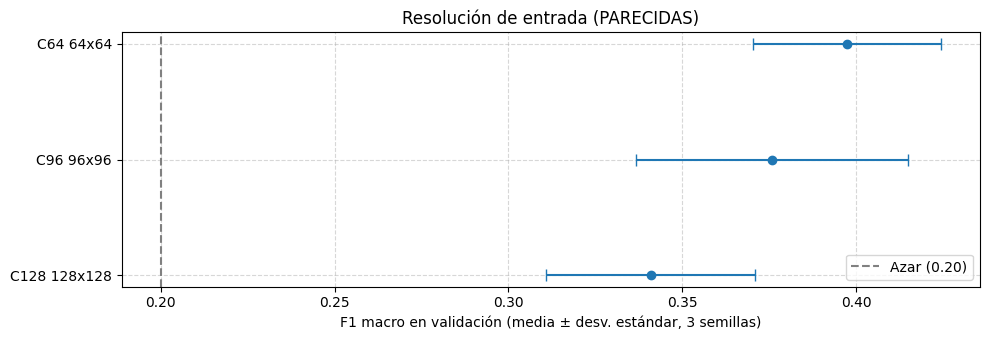


Mejor F1 macro de validación: C64 64x64 (0.397 ± 0.027)
Dentro de 1 desv. estándar de la mejor: ['C64 64x64', 'C96 96x96']
==> RESOLUCIÓN ELEGIDA: C64 64x64
==> CONFIGURACIÓN DE REFERENCIA FINAL: {'neuronas': 128, 'capas': 1, 'activacion': 'relu', 'dropout': 0.3, 'lr': 0.0001, 'aumento': True, 'estandarizar': True, 'batch': 32, 'paciencia': 20, 'resolucion': 64}
Resolución final: 64x64 | X_train: (644, 64, 64, 3)


In [17]:
# ==========================================
# PASO C (SECCIÓN 6.3): RESOLUCIÓN DE ENTRADA, 64 vs 96 vs 128 (PARECIDAS, VALIDACIÓN, 3 semillas)
# ==========================================
PASO_C = {f"C{lado} {lado}x{lado}": dict(resolucion=lado) for lado in RESOLUCIONES}
runs_C = correr_configs(PASO_C, CFG_R2, sp, SEEDS_EXP)
runs_C.to_csv("resultados/resolucion_por_semilla.csv", index=False)
res_C = resumir(runs_C)
print(res_C.to_markdown(index=False, floatfmt=".3f"))
res_C.to_csv("resultados/resolucion_resumen.csv", index=False)
grafico_f1(res_C, "Resolución de entrada (PARECIDAS)", "04d_resolucion")

mejor_C, cand_C, elegida_C = seleccionar(res_C)
CFG_REF = {**CFG_R2, **PASO_C[elegida_C]}
print(f"\nMejor F1 macro de validación: {mejor_C['config']} ({mejor_C['f1_val_media']:.3f} ± {mejor_C['f1_val_std']:.3f})")
print(f"Dentro de 1 desv. estándar de la mejor: {list(cand_C['config'])}")
print(f"==> RESOLUCIÓN ELEGIDA: {elegida_C}")
print("==> CONFIGURACIÓN DE REFERENCIA FINAL:", CFG_REF)

# A partir de aquí, los arreglos "por defecto" (X_train, X_val, X_test) pasan a la resolución elegida
RES_FINAL = CFG_REF.get("resolucion", RES_BASE)
for sp_ in SPLITS.values():
    for parte in ["train", "val", "test"]:
        sp_["X_" + parte] = sp_["XR"][RES_FINAL][parte]
print(f"Resolución final: {RES_FINAL}x{RES_FINAL} | X_train: {SPLITS['parecidas']['X_train'].shape}")

### Interpretación de la resolución
- **Resultado.** 64x64 obtuvo el mejor F1 de validación (0,397 ± 0,027), 96x96 obtuvo 0,376 ± 0,039 y 128x128 obtuvo 0,341 ± 0,030. Subir la resolución no mejoró: 96x96 queda dentro de una desviación estándar de la mejor pero con un promedio menor, y 128x128 queda claramente por debajo.
- **Costo.** Los parámetros crecen con los píxeles: 1.573.644 a 64x64, 3.539.724 a 96x96 (2,2 veces) y 6.292.236 a 128x128 (4,0 veces), con las mismas 644 imágenes de entrenamiento. Con el criterio de selección (entre configuraciones equivalentes se prefiere la más simple) se mantiene **64x64**. Los segundos por corrida (18,5; 14,0 y 20,7) no se pueden comparar porque cada resolución entrenó un número distinto de épocas.
- **Qué no se puede concluir.** El resultado no se explica por sobreajuste: el accuracy de entrenamiento a 96x96 y 128x128 (0,366 y 0,368) no es mayor que a 64x64 (0,434). Una hipótesis es que lo que usa este MLP (color y textura global) ya está en 64x64 y más píxeles solo agregan pesos, pero no se probó.
- **Alcance.** El learning rate, el tamaño de la capa y el resto se ajustaron a 64x64 y no se reajustaron para cada resolución, y el redimensionamiento usa el método por defecto de Keras (vecino más cercano). Con una sola partición y 3 semillas, el resultado respalda la elección de 64x64 pero no prueba que una resolución mayor nunca ayude.
- **Decisión.** Se mantiene 64x64 y el resto del notebook sigue sin cambios. Esto reemplaza la limitación "no se probó otra resolución".

## 7. Entrenamiento del modelo de referencia y curvas de aprendizaje (IE4)
Se entrena la configuración de referencia con la primera semilla final y se grafican las curvas de pérdida y accuracy de entrenamiento y validación, que se interpretan en función de dos referencias: el **azar** (accuracy 0,20; pérdida de un modelo que asigna 20% a cada raza = ln 5 ≈ 1,609) y la **brecha** entre entrenamiento y validación (sobreajuste si entrenamiento mejora y validación se estanca o empeora; subajuste si ambos se quedan cerca del azar).

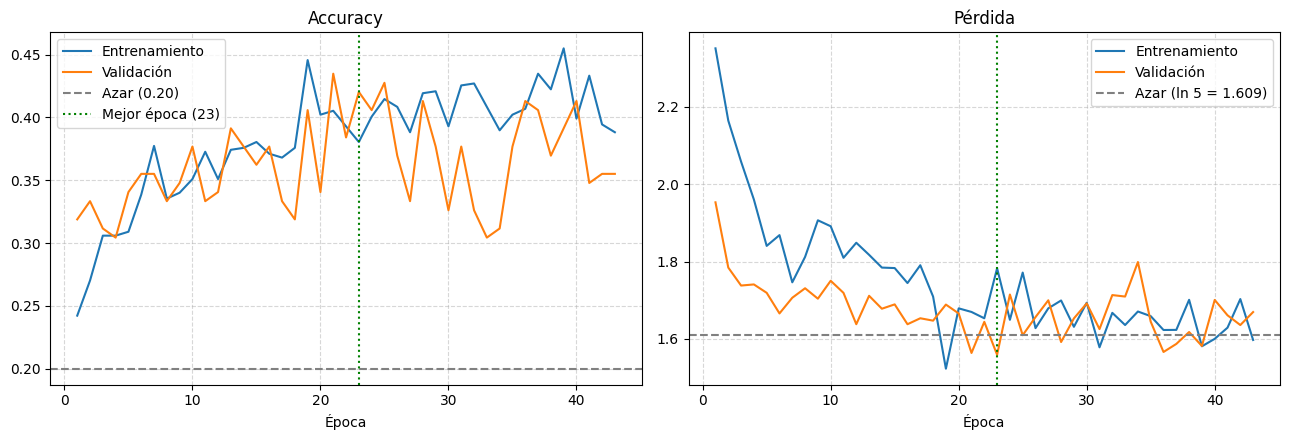

Épocas entrenadas: 43 | mejor época según val_loss: 23
Accuracy entrenamiento en esa época (con aumento y dropout activos): 0.380
Accuracy validación: 0.420 | azar: 0.200
Pérdida validación: 1.559 | pérdida del azar ln(5): 1.609
Brecha entrenamiento - validación: -0.040
Diagnóstico orientativo: ajuste razonable, sin brecha grande.


In [18]:
# ==========================================
# ENTRENAMIENTO DEL MODELO DE REFERENCIA + CURVAS
# ==========================================
sp = SPLITS["parecidas"]; clases = sp["clases"]; n = len(clases)
modelo_ref, hist_ref = entrenar(sp, SEEDS_FINAL[0], **CFG_REF)
h = hist_ref.history
mejor_ep = int(np.argmin(h["val_loss"]))

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
ep = range(1, len(h["loss"]) + 1)
ejes[0].plot(ep, h["accuracy"], label="Entrenamiento"); ejes[0].plot(ep, h["val_accuracy"], label="Validación")
ejes[0].axhline(1 / n, color="gray", linestyle="--", label=f"Azar ({1/n:.2f})")
ejes[0].axvline(mejor_ep + 1, color="green", linestyle=":", label=f"Mejor época ({mejor_ep + 1})")
ejes[0].set_title("Accuracy"); ejes[0].set_xlabel("Época"); ejes[0].legend(); ejes[0].grid(True, linestyle="--", alpha=0.5)
ejes[1].plot(ep, h["loss"], label="Entrenamiento"); ejes[1].plot(ep, h["val_loss"], label="Validación")
ejes[1].axhline(np.log(n), color="gray", linestyle="--", label=f"Azar (ln {n} = {np.log(n):.3f})")
ejes[1].axvline(mejor_ep + 1, color="green", linestyle=":")
ejes[1].set_title("Pérdida"); ejes[1].set_xlabel("Época"); ejes[1].legend(); ejes[1].grid(True, linestyle="--", alpha=0.5)
plt.tight_layout(); guardar_fig("05_curvas_modelo_referencia"); plt.show()

acc_tr, acc_va = h["accuracy"][mejor_ep], h["val_accuracy"][mejor_ep]
print(f"Épocas entrenadas: {len(h['loss'])} | mejor época según val_loss: {mejor_ep + 1}")
print(f"Accuracy entrenamiento en esa época (con aumento y dropout activos): {acc_tr:.3f}")
print(f"Accuracy validación: {acc_va:.3f} | azar: {1/n:.3f}")
print(f"Pérdida validación: {h['val_loss'][mejor_ep]:.3f} | pérdida del azar ln({n}): {np.log(n):.3f}")
print(f"Brecha entrenamiento - validación: {acc_tr - acc_va:+.3f}")
if acc_tr - 1 / n < 0.10:
    print("Diagnóstico orientativo: SUBAJUSTE (el accuracy de entrenamiento queda a menos de 10 puntos del azar).")
elif acc_tr - acc_va > 0.10:
    print("Diagnóstico orientativo: posible SOBREAJUSTE (brecha mayor a 10 puntos).")
else:
    print("Diagnóstico orientativo: ajuste razonable, sin brecha grande.")

In [19]:
hh = hist_ref.history
print(f"Accuracy de validación: mín {min(hh['val_accuracy']):.3f} (época {int(np.argmin(hh['val_accuracy']))+1}) | máx {max(hh['val_accuracy']):.3f} (época {int(np.argmax(hh['val_accuracy']))+1})")
print(f"Pérdida de validación: mín {min(hh['val_loss']):.3f} | máx {max(hh['val_loss']):.3f}")

Accuracy de validación: mín 0.304 (época 4) | máx 0.435 (época 21)
Pérdida de validación: mín 1.559 | máx 1.953


### Interpretación de las curvas
- **Convergencia.** La mejor pérdida de validación (1,559) se alcanzó en la **época 23**, y `EarlyStopping` detuvo el entrenamiento en la época 43, tras 20 épocas sin mejorar (la paciencia de la configuración final). El número de épocas sale de los datos y no de una cifra fijada a ojo. La mejor época depende de la semilla: en la sección 6 el promedio con 3 semillas fue 46,7, y en esta corrida fue 23.
- **Aprende, pero poco en términos de pérdida.** En la mejor época el accuracy de entrenamiento es 0,380 y el de validación 0,420, claramente sobre el azar (0,20). Pero la pérdida de validación (1,559) es apenas 0,05 menor que la del azar (ln 5 = 1,609) y se mueve cerca de esa referencia durante casi todo el entrenamiento. Que el accuracy llegue a 0,42 y la pérdida siga cerca del azar sugiere que el modelo se equivoca con mucha seguridad en varias imágenes; la sección 9 lo confirma con las probabilidades.
- **Sobre el diagnóstico automático.** La celda imprime "ajuste razonable, sin brecha grande". Es una regla gruesa que solo compara accuracies. Se interpreta así: no hay sobreajuste (entrenamiento y validación son parecidos) ni un subajuste extremo (el accuracy de entrenamiento está 18 puntos sobre el azar), pero el aprendizaje es limitado.
- **Validación sobre entrenamiento.** La brecha es de −0,040 (la validación es mayor). No significa que el modelo generalice mejor: el accuracy de entrenamiento se mide con aumento de datos y dropout activos, lo que lo vuelve pesimista, y la validación tiene solo 138 imágenes.
- **Estabilidad.** Según el gráfico, el accuracy de validación oscila entre 0,304 (época 4) y 0,435 (época 21). Con 138 imágenes cada una vale unos 0,7 puntos, así que un salto de 13 puntos equivale a unas 18 imágenes. La pérdida de validación parte cerca de 1,95, sobre el azar (las primeras predicciones son seguras y erradas), y después se mueve aproximadamente entre 1,56 y 1,80, por eso conviene usarla y no el accuracy para decidir cuándo detenerse.
- **Conclusión.** El modelo aprende algo, pero poco. Con esta configuración más épocas probablemente no cambien mucho el panorama; la mejora de fondo esperada viene de una arquitectura que aproveche la estructura de la imagen (CNN).

## 8. Evaluación del desempeño en el set de prueba (IE5)
El set de prueba no se usó para entrenar ni para elegir entre configuraciones (la selección se hizo solo con validación). La única influencia indirecta es la declarada en la sección 6.2: la ronda 2 se diseñó tras ver un resultado en prueba de una ejecución anterior, así que la independencia no es total.La configuración de referencia se entrena con **5 semillas** y se reporta media ± desviación estándar. Para el análisis detallado (matriz de confusión, ejemplos) se usa el modelo de la primera semilla.

**Qué aporta cada métrica en este problema:**
- **Accuracy:** proporción total de aciertos; se compara con el azar (0,20).
- **Precision (por raza):** cuando el modelo dice "Ragdoll", ¿qué proporción realmente lo es? Baja precisión significa que la raza se usa como "comodín".
- **Recall (por raza):** de los gatos de cierta raza, ¿cuántos detecta? Es la métrica que controla el KPI secundario: un recall cercano a 0 indica una raza ignorada.
- **F1-Score:** combina precision y recall por raza; el **F1 macro** promedia las 5 razas con igual peso (KPI principal).
- **Matriz de confusión:** muestra **qué razas se confunden entre sí**, información que las métricas resumidas no entregan.

In [20]:
# ==========================================
# EVALUACIÓN FINAL EN TEST: 5 SEMILLAS + KPIs
# ==========================================
def evaluar_semillas(nombre, seeds, cfg, modelo_inicial=None):
    sp = SPLITS[nombre]; filas = []; primero = None
    X_test = sp["XR"][cfg.get("resolucion", RES_BASE)]["test"]
    for s in seeds:
        if modelo_inicial is not None and s == seeds[0]:
            m = modelo_inicial
        else:
            m, _ = entrenar(sp, s, **cfg)
        met, pred = metricas(m, X_test, sp["y_test"])
        filas.append(dict(semilla=s, **met))
        if primero is None:
            primero = (m, pred)
    return pd.DataFrame(filas), primero

fin_par, (modelo_ref, pred_ref) = evaluar_semillas("parecidas", SEEDS_FINAL, CFG_REF, modelo_inicial=modelo_ref)
print("Resultados en TEST - subconjunto PARECIDAS, por semilla:")
print(fin_par.to_markdown(index=False, floatfmt=".3f"))

f1_m, f1_s = fin_par["f1"].mean(), fin_par["f1"].std()
acc_m, acc_s = fin_par["acc"].mean(), fin_par["acc"].std()
rm_m = fin_par["recall_min"].mean()
print(f"\nAccuracy: {acc_m:.3f} ± {acc_s:.3f} | F1 macro: {f1_m:.3f} ± {f1_s:.3f} | Recall mínimo (media): {rm_m:.3f}")
print(f"KPI principal  (F1 macro >= {KPI_F1_MACRO}):     {f1_m:.3f} -> {'CUMPLE' if f1_m >= KPI_F1_MACRO else 'NO CUMPLE'}")
print(f"KPI secundario (recall mínimo >= {KPI_RECALL_MIN}): {rm_m:.3f} -> {'CUMPLE' if rm_m >= KPI_RECALL_MIN else 'NO CUMPLE'}")
fin_par.to_csv("resultados/test_parecidas_por_semilla.csv", index=False)

Resultados en TEST - subconjunto PARECIDAS, por semilla:
|   semilla |   acc |    f1 |   recall_min |
|----------:|------:|------:|-------------:|
|   101.000 | 0.333 | 0.320 |        0.214 |
|   102.000 | 0.435 | 0.430 |        0.286 |
|   103.000 | 0.370 | 0.366 |        0.259 |
|   104.000 | 0.341 | 0.347 |        0.250 |
|   105.000 | 0.348 | 0.351 |        0.259 |

Accuracy: 0.365 ± 0.041 | F1 macro: 0.363 ± 0.041 | Recall mínimo (media): 0.254
KPI principal  (F1 macro >= 0.4):     0.363 -> NO CUMPLE
KPI secundario (recall mínimo >= 0.2): 0.254 -> CUMPLE


In [21]:
# ==========================================
# COMPARACIÓN EN TEST: CONFIGURACIÓN DE LA RONDA 1 vs. CONFIGURACIÓN FINAL
# (solo informativa: la configuración final se eligió con validación, no con esta tabla)
# ==========================================
if CFG_R1 == CFG_REF:
    print("La ronda 2 y la resolución mantuvieron la configuración de la ronda 1: no hay nada que comparar.")
else:
    fin_r1, _ = evaluar_semillas("parecidas", SEEDS_FINAL, CFG_R1)
    def ms(d, c): return f"{d[c].mean():.3f} ± {d[c].std():.3f}"
    comp_r = pd.DataFrame({
        "configuración": ["ronda 1", "final"],
        "accuracy": [ms(fin_r1, "acc"), ms(fin_par, "acc")],
        "F1 macro": [ms(fin_r1, "f1"), ms(fin_par, "f1")],
        "recall mínimo": [ms(fin_r1, "recall_min"), ms(fin_par, "recall_min")],
    })
    print(comp_r.to_markdown(index=False))
    dif = fin_par["f1"].mean() - fin_r1["f1"].mean()
    print(f"\nDiferencia de F1 macro (final - ronda 1): {dif:+.3f}")
    print(f"Suma de las desviaciones estándar entre semillas: {fin_par['f1'].std() + fin_r1['f1'].std():.3f}")
    comp_r.to_csv("resultados/comparacion_ronda1_vs_final.csv", index=False)

| configuración   | accuracy      | F1 macro      | recall mínimo   |
|:----------------|:--------------|:--------------|:----------------|
| ronda 1         | 0.286 ± 0.041 | 0.272 ± 0.052 | 0.110 ± 0.072   |
| final           | 0.365 ± 0.041 | 0.363 ± 0.041 | 0.254 ± 0.026   |

Diferencia de F1 macro (final - ronda 1): +0.091
Suma de las desviaciones estándar entre semillas: 0.093


              precision    recall  f1-score   support

      Birman      0.273     0.222     0.245        27
     Ragdoll      0.306     0.536     0.390        28
     Siamese      0.400     0.214     0.279        28
     Persian      0.353     0.214     0.267        28
  Maine_Coon      0.371     0.481     0.419        27

    accuracy                          0.333       138
   macro avg      0.341     0.334     0.320       138
weighted avg      0.341     0.333     0.320       138



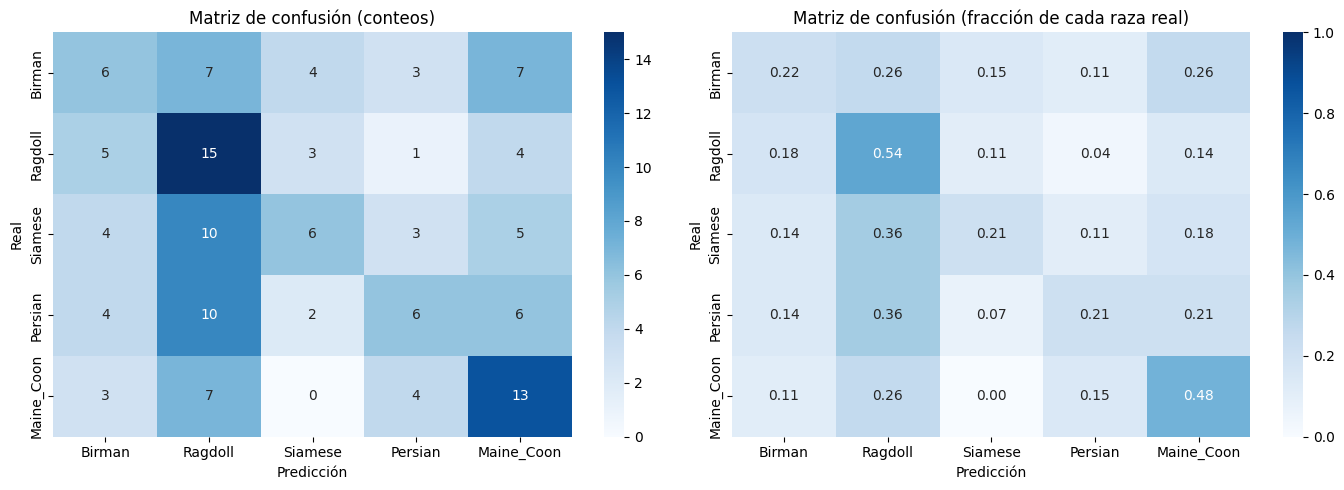

Confusiones más frecuentes (real -> predicho):
  Siamese -> Ragdoll: 10 de 28 imágenes (36%)
  Persian -> Ragdoll: 10 de 28 imágenes (36%)
  Maine_Coon -> Ragdoll: 7 de 27 imágenes (26%)
  Birman -> Ragdoll: 7 de 27 imágenes (26%)
  Birman -> Maine_Coon: 7 de 27 imágenes (26%)

Accuracy = 46/138 = 0.333 | IC 95%: [0.260, 0.416] | azar = 0.20
Prueba binomial (H1: accuracy > azar): p = 0.0001649


In [22]:
# ==========================================
# DETALLE DEL MODELO DE LA PRIMERA SEMILLA: REPORTE, MATRIZ DE CONFUSIÓN Y SIGNIFICANCIA
# ==========================================
sp = SPLITS["parecidas"]; clases = sp["clases"]; n = len(clases)
yte = sp["y_test"]
print(classification_report(yte, pred_ref, target_names=clases, digits=3, zero_division=0))

cm = confusion_matrix(yte, pred_ref)
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=clases, yticklabels=clases, ax=ejes[0])
ejes[0].set_title("Matriz de confusión (conteos)"); ejes[0].set_xlabel("Predicción"); ejes[0].set_ylabel("Real")
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            xticklabels=clases, yticklabels=clases, ax=ejes[1])
ejes[1].set_title("Matriz de confusión (fracción de cada raza real)"); ejes[1].set_xlabel("Predicción"); ejes[1].set_ylabel("Real")
plt.tight_layout(); guardar_fig("06_matriz_confusion_parecidas"); plt.show()

pares = [(cm[i, j], clases[i], clases[j], cm[i].sum()) for i in range(n) for j in range(n) if i != j]
pares.sort(reverse=True)
print("Confusiones más frecuentes (real -> predicho):")
for c, a, b, tot in pares[:5]:
    print(f"  {a} -> {b}: {c} de {tot} imágenes ({c / tot:.0%})")

# ¿El accuracy supera al azar de forma estadísticamente distinguible? (un solo modelo, 138 imágenes de prueba)
k, N = int((pred_ref == yte).sum()), len(yte)
p_val = binomtest(k, N, 1 / n, alternative="greater").pvalue
ic = binomtest(k, N).proportion_ci(confidence_level=0.95, method="wilson")
print(f"\nAccuracy = {k}/{N} = {k/N:.3f} | IC 95%: [{ic.low:.3f}, {ic.high:.3f}] | azar = {1/n:.2f}")
print(f"Prueba binomial (H1: accuracy > azar): p = {p_val:.4g}")

### Interpretación de las métricas (modelo de la primera semilla, salvo que se indique otra cosa)
- **Accuracy y azar.** Acertó 46 de 138 imágenes (0,333; IC 95% de Wilson: 0,260 a 0,416). La prueba binomial contra el azar de 0,20 da p = 0,00016, así que se distingue del azar con claridad: el límite inferior del intervalo (0,260) queda sobre 0,20. Con las 5 semillas el accuracy es 0,365 ± 0,041 (entre 0,333 y 0,435); la primera semilla es la de menor accuracy, así que el modelo detallado es algo más pesimista que el promedio.
- **Precision y recall por raza.** Ragdoll tiene el mayor recall (0,536) y baja precisión (0,306): el modelo la usa como **comodín** (la predijo 49 veces de 138, un 36%, y solo 15 fueron correctas). Maine_Coon tiene el mejor F1 (0,419) y Birman el peor (0,245). Siamese y Persian tienen recall 0,214 (6 de 28 cada una). Ninguna raza queda ignorada en esta semilla.
- **F1 macro y KPIs.** F1 macro **0,363 ± 0,041** (meta ≥ 0,40): **no se cumple el KPI principal**, aunque queda cerca (0,037 bajo la meta) y una semilla (la 102) llega a 0,430. El recall mínimo medio es **0,254 ± 0,026** (meta ≥ 0,20): **se cumple el KPI secundario**, y las 5 semillas lo superan (la menor es 0,214). Los umbrales se mantuvieron tal como se fijaron antes de entrenar.
- **Matriz de confusión.** Cuatro de las cinco confusiones más frecuentes terminan en Ragdoll: Siamese → Ragdoll (10 de 28, 36%), Persian → Ragdoll (10 de 28, 36%), Maine_Coon → Ragdoll (7 de 27, 26%) y Birman → Ragdoll (7 de 27, 26%). La quinta es Birman → Maine_Coon (7 de 27, 26%). La hipótesis previa anticipaba la confusión Birman–Siamese y **no se cumplió como confusión dominante**: Birman → Siamese es 4 de 27 (15%) y Siamese → Birman 4 de 28 (14%). Lo que domina es Ragdoll como clase "por defecto".
- **Validación vs. prueba.** El F1 de validación de esta configuración (0,397) es mayor que el de prueba (0,363). Es esperable cuando la configuración se elige por su desempeño en validación, y la diferencia (0,034) es menor que la desviación entre semillas.
- **Mejora respecto de la ronda 1.** Con la configuración de la ronda 1 (M3) el F1 macro en prueba fue 0,272 ± 0,052 y el recall mínimo 0,110; con la final, 0,363 ± 0,041 y 0,254. La diferencia de F1 (+0,091) es parecida a la suma de las desviaciones entre semillas (0,093): la mejora es consistente, pero no abrumadora con 5 semillas.
- **Impacto en el negocio.** El modelo se equivoca en 92 de 138 imágenes (67%): el personal de la clínica tendría que corregir la raza en unas 2 de cada 3 fichas. Además, muchas equivocaciones son con alta confianza (sección 9). **No es utilizable como apoyo en producción**; hoy sirve como línea base para comparar modelos mejores.

## 9. Análisis de aciertos y errores (IE5)
Se muestran ejemplos **elegidos al azar con semilla fija** (no a mano) de aciertos y errores del modelo de referencia, con la probabilidad que asignó a la raza predicha. Las imágenes se muestran a 64x64, que es lo que realmente ve el modelo. Con pocos ejemplos no se puede afirmar un patrón: lo que se observe aquí son **hipótesis**, no conclusiones.

Aciertos: 46 | Errores: 92 de 138


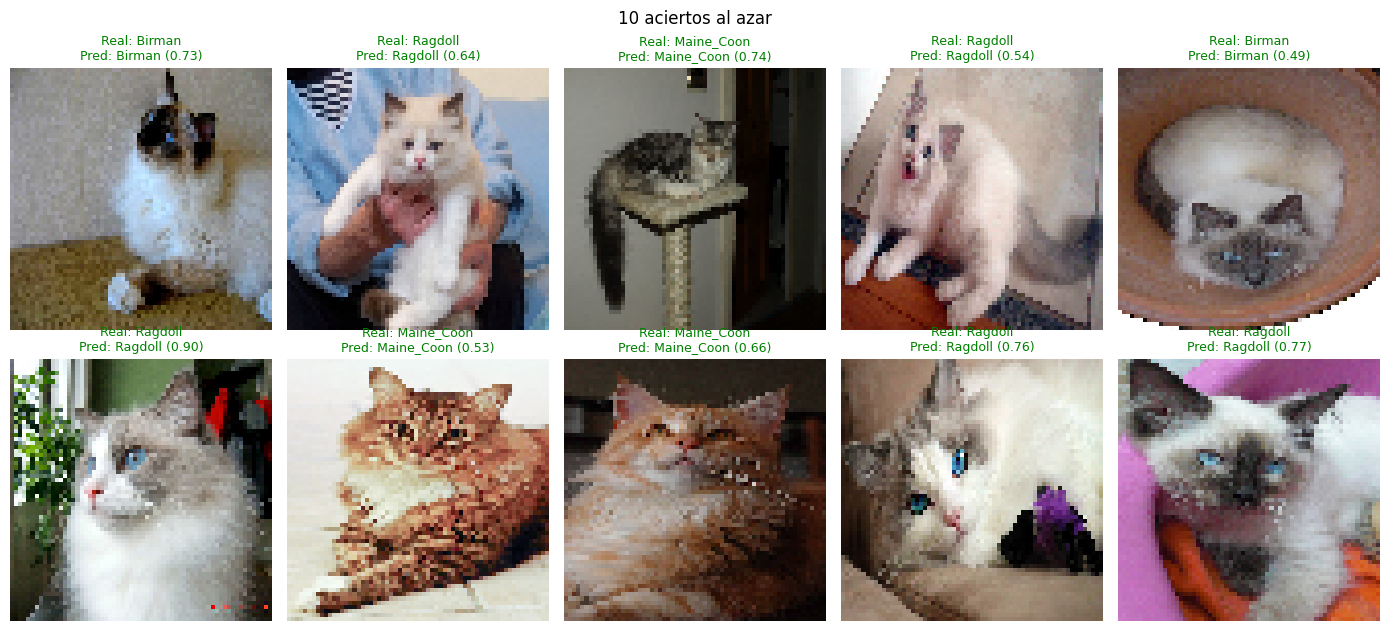

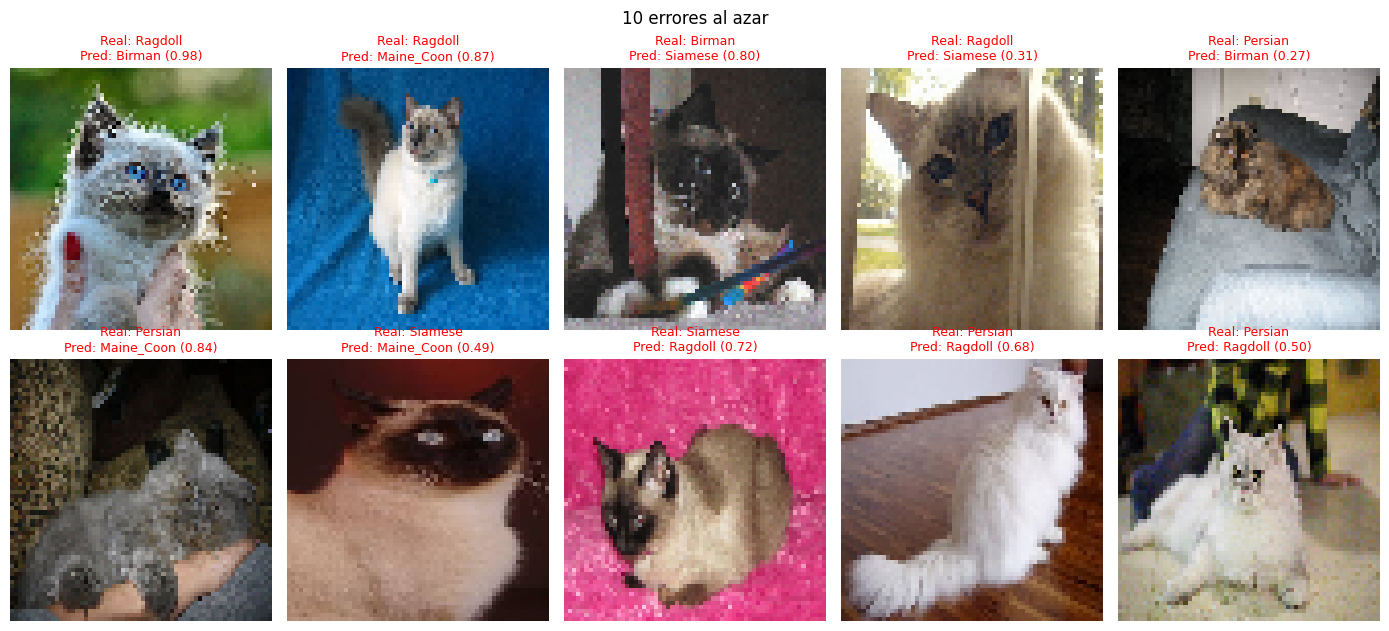

Par más confundido: real Siamese -> predicho Ragdoll (10 imágenes)


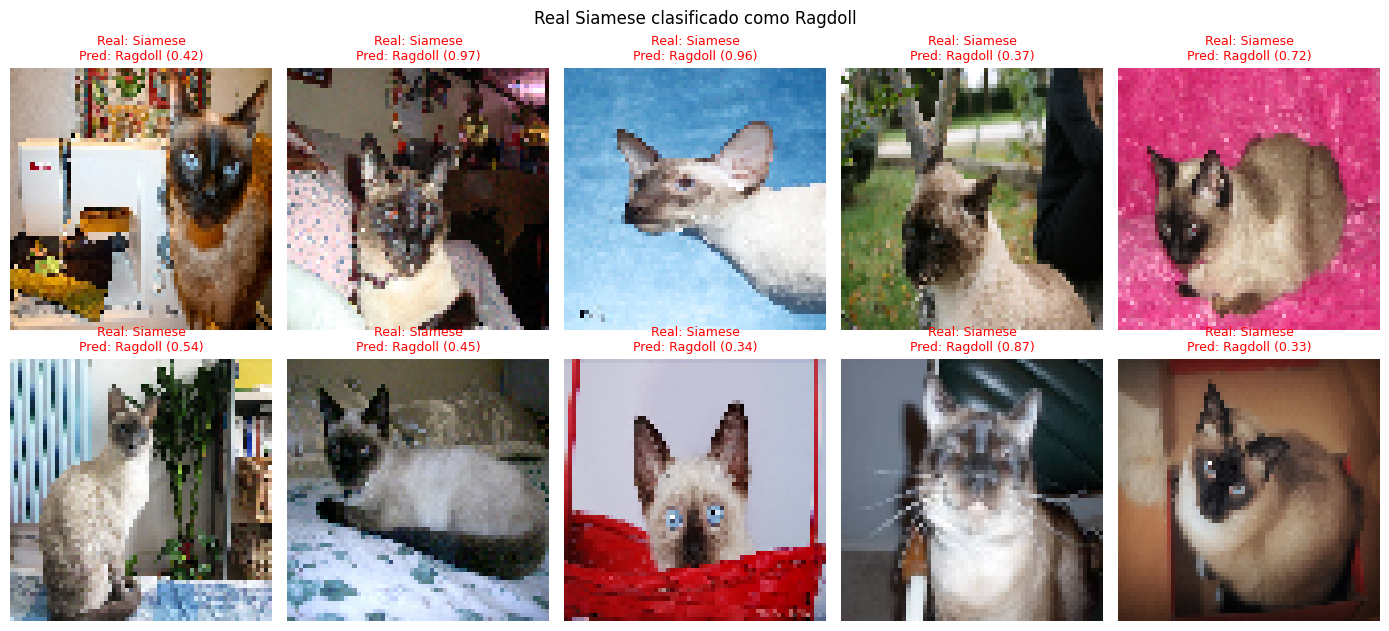

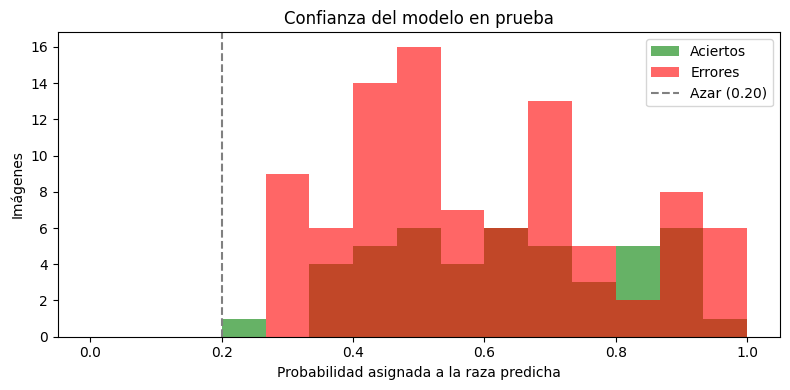

Confianza media: aciertos 0.637 | errores 0.588 | máxima observada 0.992


In [23]:
# ==========================================
# EJEMPLOS BIEN Y MAL CLASIFICADOS + CONFIANZA DEL MODELO
# ==========================================
sp = SPLITS["parecidas"]; clases = sp["clases"]
Xte, yte = sp["X_test"], sp["y_test"]
probs = modelo_ref.predict(Xte, verbose=0)
pred = probs.argmax(axis=1); conf = probs.max(axis=1)
ok = np.where(pred == yte)[0]; mal = np.where(pred != yte)[0]
print(f"Aciertos: {len(ok)} | Errores: {len(mal)} de {len(yte)}")
rng = np.random.default_rng(SEED_SPLIT)

def galeria(indices, titulo, color, archivo, k=10):
    idx = rng.choice(indices, min(k, len(indices)), replace=False)
    fig, ejes = plt.subplots(2, 5, figsize=(14, 6.5))
    for ax, i in zip(ejes.ravel(), idx):
        ax.imshow(Xte[i].astype("uint8")); ax.axis("off")
        ax.set_title(f"Real: {clases[yte[i]]}\nPred: {clases[pred[i]]} ({conf[i]:.2f})", color=color, fontsize=9)
    for ax in ejes.ravel()[len(idx):]:
        ax.axis("off")
    plt.suptitle(titulo); plt.tight_layout(); guardar_fig(archivo); plt.show()

galeria(ok, "10 aciertos al azar", "green", "07_aciertos")
galeria(mal, "10 errores al azar", "red", "08_errores")

# Ejemplos del par de razas más confundido (real a -> predicho b)
cm = confusion_matrix(yte, pred)
n = len(clases)
a, b = max(((i, j) for i in range(n) for j in range(n) if i != j), key=lambda t: cm[t[0], t[1]])
idx_par = np.where((yte == a) & (pred == b))[0]
print(f"Par más confundido: real {clases[a]} -> predicho {clases[b]} ({len(idx_par)} imágenes)")
if len(idx_par) > 0:
    galeria(idx_par, f"Real {clases[a]} clasificado como {clases[b]}", "red", "09_par_mas_confundido", k=min(10, len(idx_par)))

# Confianza del modelo: aciertos vs errores
plt.figure(figsize=(8, 4))
plt.hist(conf[ok], bins=15, range=(0, 1), alpha=0.6, label="Aciertos", color="green")
plt.hist(conf[mal], bins=15, range=(0, 1), alpha=0.6, label="Errores", color="red")
plt.axvline(1 / n, color="gray", linestyle="--", label=f"Azar ({1/n:.2f})")
plt.xlabel("Probabilidad asignada a la raza predicha"); plt.ylabel("Imágenes"); plt.legend()
plt.title("Confianza del modelo en prueba"); plt.tight_layout(); guardar_fig("10_confianza"); plt.show()
print(f"Confianza media: aciertos {conf[ok].mean():.3f} | errores {conf[mal].mean():.3f} | máxima observada {conf.max():.3f}")

### Interpretación del análisis de errores
Son 10 aciertos y 10 errores elegidos al azar, y 10 imágenes del par más confundido. Es una muestra pequeña, así que lo que sigue son **hipótesis, no conclusiones**.
- **Aciertos.** 5 son Ragdoll, 3 Maine_Coon (dos de tonos naranjos y uno atigrado gris) y 2 Birman; no aparece ningún Siamese ni Persian. Es coherente con el recall bajo de esas dos razas (0,214) y con la tendencia del modelo a predecir Ragdoll, que puede inflar esos aciertos.
- **Errores.** En 6 de los 10 errores el gato tiene patrón colorpoint (cara oscura sobre cuerpo claro): 3 Ragdoll (predichos como Birman, Maine_Coon y Siamese), 1 Birman (predicho Siamese) y 2 Siamese (predichos Maine_Coon y Ragdoll). Los otros 4 son Persian: dos blancos de pelo largo predichos como Ragdoll, uno gris predicho como Maine_Coon y uno oscuro y pequeño en la imagen predicho como Birman. Varios errores tienen además fondos de color intenso (azul, verde, rosa) o encuadres poco comunes, y a 64x64 se pierde detalle de orejas, hocico y largo del pelaje. Esto podría ser parte de la causa, pero no se probó.
- **Par más confundido (Siamese → Ragdoll).** Las 10 imágenes mostradas tienen el patrón colorpoint (cara, orejas y cola oscuras sobre cuerpo claro, y en varias ojos azules), que también es un rasgo de Ragdoll. En este par la confusión sí parece deberse a un parecido de patrón. Es una hipótesis: tendría que probarse, por ejemplo, con imágenes en escala de grises. Varias fotos tienen además fondos intensos (celeste, rosa, rojo).
- **Confianza.** La probabilidad asignada a la raza predicha es parecida en aciertos (0,637) y en errores (0,588), y el máximo observado es 0,992. En la galería de errores hay equivocaciones con 0,98, 0,87, 0,84 y 0,80. El modelo no distingue bien cuándo acierta, así que su confianza no sirve para filtrar predicciones dudosas. Además está **sobreconfiado**: la confianza promedio global es de aproximadamente 0,60 (promedio ponderado de las dos medias) mientras que el accuracy es 0,33.
- **Impacto ético.** Un sistema que asigna razas con errores frecuentes y con alta confianza puede llevar a registrar mal una ficha o a sugerir controles preventivos inadecuados, por lo que solo debería usarse como apoyo con confirmación humana. Además, el dataset son fotografías de internet de pocas razas, y no representa a los gatos mestizos, que son la mayoría en la práctica.

## 10. Comparación entre subconjuntos: PARECIDAS vs. DISTINTAS (IE1, IE5)
Se entrena la **misma configuración de referencia** (elegida con PARECIDAS, sin reajustarla) sobre el subconjunto DISTINTAS, con las mismas 5 semillas, y se compara con PARECIDAS en el set de prueba. Esto pone a prueba la hipótesis de la sección 1.2.

**Precaución:** la configuración se eligió con PARECIDAS, lo que podría favorecerla levemente; y ambos subconjuntos usan una sola partición de datos, por lo que la desviación entre semillas mide la variación por inicialización, no por muestreo.

| subconjunto   | accuracy      | F1 macro      | recall mínimo   |
|:--------------|:--------------|:--------------|:----------------|
| parecidas     | 0.365 ± 0.041 | 0.363 ± 0.041 | 0.254 ± 0.026   |
| distintas     | 0.490 ± 0.036 | 0.487 ± 0.037 | 0.360 ± 0.059   |

Diferencia de F1 macro (distintas - parecidas): +0.124
Suma de las desviaciones estándar entre semillas: 0.079
KPI F1 macro >= 0.4 en distintas: CUMPLE


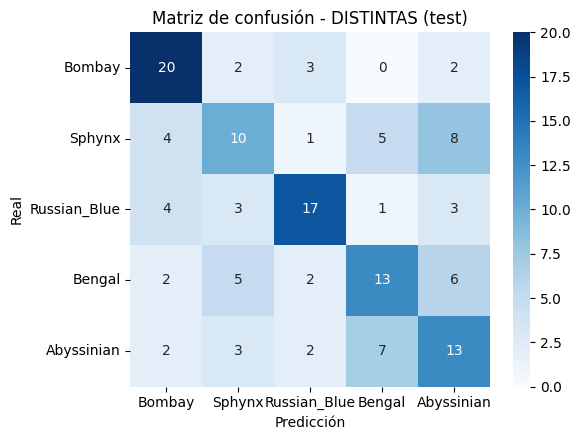

              precision    recall  f1-score   support

      Bombay      0.625     0.741     0.678        27
      Sphynx      0.435     0.357     0.392        28
Russian_Blue      0.680     0.607     0.642        28
      Bengal      0.500     0.464     0.481        28
  Abyssinian      0.406     0.481     0.441        27

    accuracy                          0.529       138
   macro avg      0.529     0.530     0.527       138
weighted avg      0.529     0.529     0.526       138



In [24]:
# ==========================================
# CONTRASTE: MISMA CONFIGURACIÓN SOBRE DISTINTAS (5 semillas, TEST)
# ==========================================
fin_dis, (modelo_dis, pred_dis) = evaluar_semillas("distintas", SEEDS_FINAL, CFG_REF)

comp = pd.DataFrame({
    "subconjunto": ["parecidas", "distintas"],
    "accuracy": [f"{fin_par['acc'].mean():.3f} ± {fin_par['acc'].std():.3f}", f"{fin_dis['acc'].mean():.3f} ± {fin_dis['acc'].std():.3f}"],
    "F1 macro": [f"{fin_par['f1'].mean():.3f} ± {fin_par['f1'].std():.3f}", f"{fin_dis['f1'].mean():.3f} ± {fin_dis['f1'].std():.3f}"],
    "recall mínimo": [f"{fin_par['recall_min'].mean():.3f} ± {fin_par['recall_min'].std():.3f}", f"{fin_dis['recall_min'].mean():.3f} ± {fin_dis['recall_min'].std():.3f}"],
})
print(comp.to_markdown(index=False))
dif = fin_dis["f1"].mean() - fin_par["f1"].mean()
print(f"\nDiferencia de F1 macro (distintas - parecidas): {dif:+.3f}")
print(f"Suma de las desviaciones estándar entre semillas: {fin_dis['f1'].std() + fin_par['f1'].std():.3f}")
print(f"KPI F1 macro >= {KPI_F1_MACRO} en distintas: {'CUMPLE' if fin_dis['f1'].mean() >= KPI_F1_MACRO else 'NO CUMPLE'}")
comp.to_csv("resultados/comparacion_subconjuntos.csv", index=False)

# Matriz de confusión de DISTINTAS
cl = SPLITS["distintas"]["clases"]; cm_d = confusion_matrix(SPLITS["distintas"]["y_test"], pred_dis)
plt.figure(figsize=(6, 4.5))
sns.heatmap(cm_d, annot=True, fmt="d", cmap="Blues", xticklabels=cl, yticklabels=cl)
plt.title("Matriz de confusión - DISTINTAS (test)"); plt.xlabel("Predicción"); plt.ylabel("Real")
plt.tight_layout(); guardar_fig("11_matriz_confusion_distintas"); plt.show()
print(classification_report(SPLITS["distintas"]["y_test"], pred_dis, target_names=cl, digits=3, zero_division=0))

### Interpretación de la comparación entre subconjuntos
- **Hipótesis: se cumple.** El MLP rindió mejor en DISTINTAS: F1 macro **0,487 ± 0,037**, contra **0,363 ± 0,041** en PARECIDAS. La diferencia es de **+0,124**, unas 1,6 veces la suma de las desviaciones entre semillas (0,079), así que no se explica solo por la variación de la inicialización. El accuracy sigue el mismo patrón (0,490 ± 0,036 contra 0,365 ± 0,041; azar 0,20).
- **KPIs en DISTINTAS.** Se cumplen los dos: F1 macro 0,487 frente a la meta de 0,40 (margen de 0,087, más de dos desviaciones estándar) y recall mínimo 0,360 ± 0,059 frente a la meta de 0,20. La configuración no se reajustó para DISTINTAS.
- **Relación con la similitud de la sección 4.** Las razas de PARECIDAS estaban entre 24% y 27% más cerca entre sí que las de DISTINTAS, y el resultado va en esa dirección: mejor desempeño donde las razas son más distinguibles. Esas medidas solo capturan color global, así que son un indicio y no una prueba.
- **Razas concretas (primera semilla: accuracy 0,529 y F1 macro 0,527).** Bombay tiene el mejor F1 (0,678; precision 0,625 y recall 0,741) y le sigue Russian_Blue (0,642). Sphynx tiene el peor (0,392; recall 0,357): 8 de 28 se clasificaron como Abyssinian y 5 como Bengal. Bengal y Abyssinian se confunden entre sí (6 de 28 Bengal como Abyssinian y 7 de 27 Abyssinian como Bengal), y son justamente el par más cercano de DISTINTAS en la sección 4 (distancia 0,0743), lo que respalda esa medida de similitud. A diferencia de PARECIDAS, aquí no hay una raza comodín: las predicciones se reparten entre 23 y 32 por raza (de 138), mientras que Ragdoll recibió 49 en PARECIDAS.
- **Nota sobre las cifras.** La tabla comparativa usa la media de 5 semillas (F1 macro 0,487). El reporte por raza y la matriz de confusión corresponden a la **primera semilla** (F1 macro 0,527, accuracy 0,529), por eso difieren de la tabla: esa semilla rindió por sobre el promedio.
- **Qué dice del MLP.** Las razas de color liso y distintivo (Bombay negro, Russian_Blue gris) se reconocen mejor, y las que comparten tonos cálidos o dependen de un patrón fino (Bengal, Abyssinian, Sphynx) peor. Es coherente con un modelo que se apoya sobre todo en color y textura global, pero con solo 5 razas y una partición no lo demuestra.
- **Precaución.** La configuración se eligió con PARECIDAS; si eso la favoreció, la ventaja habría sido para PARECIDAS, y aun así DISTINTAS rindió mejor. Hay una sola partición de datos y 138 imágenes de prueba, y el modelo sigue lejos de ser utilizable sin supervisión: con accuracy medio de 0,490 se equivoca en cerca de la mitad de las imágenes.

## 11. Limitaciones del MLP en imágenes y conclusiones (IE5, IE6)
### Limitaciones del MLP para clasificar imágenes
1. **Pérdida de estructura espacial:** `Flatten` convierte la imagen en un vector y destruye la vecindad entre píxeles. La red no sabe que un píxel está al lado de otro, así que no puede aprender formas locales como orejas, hocico o el patrón de la cara, que son justamente lo que distingue a razas parecidas.
2. **Crecimiento de parámetros con la resolución:** la primera capa densa tiene (entradas × neuronas + sesgos) pesos y crece con el tamaño de la imagen. Con 128 neuronas pasa de 393.344 pesos a 32x32 a 1.572.992 a 64x64 y a 19.267.712 a 224x224, unas 12 veces más que a 64x64 (se calcula abajo). En la sección 6.3 se midió el efecto: a 96x96 (2,2 veces los parámetros) y a 128x128 (4 veces) el F1 de validación no mejoró (0,376 y 0,341 contra 0,397 a 64x64).
3. **Sin invarianza a traslaciones:** un gato desplazado en la imagen activa pesos distintos; el aumento de datos mitiga esto, pero no lo resuelve.
4. **Muchos parámetros para pocos datos:** con 644 imágenes de entrenamiento, el riesgo de memorizar o de no aprender un criterio estable es alto.
5. **Sensibilidad a la configuración:** los resultados cambian con la semilla y los hiperparámetros (se cuantificó en la sección 6).

In [25]:
# ==========================================
# PARÁMETROS DE LA PRIMERA CAPA Y CRECIMIENTO CON LA RESOLUCIÓN
# ==========================================
neuronas = CFG_REF["neuronas"]
n_train = len(SPLITS["parecidas"]["X_train"])
print(f"Parámetros totales del modelo de referencia: {modelo_ref.count_params():,}")
print(f"Imágenes de entrenamiento: {n_train} -> {modelo_ref.count_params() / n_train:,.0f} parámetros por imagen")
for lado in [32, 64, 128, 224]:
    entradas = lado * lado * 3
    print(f"Resolución {lado}x{lado}: {entradas:>7,} entradas -> primera capa ({neuronas} neuronas): {entradas * neuronas + neuronas:>12,} pesos")

Parámetros totales del modelo de referencia: 1,573,644
Imágenes de entrenamiento: 644 -> 2,444 parámetros por imagen
Resolución 32x32:   3,072 entradas -> primera capa (128 neuronas):      393,344 pesos
Resolución 64x64:  12,288 entradas -> primera capa (128 neuronas):    1,572,992 pesos
Resolución 128x128:  49,152 entradas -> primera capa (128 neuronas):    6,291,584 pesos
Resolución 224x224: 150,528 entradas -> primera capa (128 neuronas):   19,267,712 pesos


### Conclusiones
- **Desempeño y KPIs.** En prueba (5 semillas) sobre PARECIDAS, el F1 macro fue **0,363 ± 0,041** (meta ≥ 0,40) y el recall mínimo medio **0,254 ± 0,026** (meta ≥ 0,20): **no se cumplió el KPI principal y sí el secundario.** Sobre DISTINTAS, el F1 macro fue **0,487 ± 0,037** y el recall mínimo **0,360 ± 0,059**: **se cumplieron ambos.** El accuracy fue 0,365 ± 0,041 en PARECIDAS y 0,490 ± 0,036 en DISTINTAS, frente a un azar de 0,20. En PARECIDAS el modelo se equivoca en 67% de las imágenes de prueba, y en DISTINTAS en cerca de la mitad: no es utilizable en la clínica sin confirmación humana. Los umbrales no se modificaron después de ver los resultados.
- **Decisiones de diseño.** Configuración final: 1 capa oculta de 128 neuronas con ReLU, dropout 0,3, batch 32, learning rate 1e-4, estandarización por canal, aumento de datos, `EarlyStopping` con paciencia 20 y entrada de 64x64. Lo que más importó fue cómo se entrena: estandarizar las entradas y bajar el learning rate llevaron el F1 de validación de 0,134 a 0,397. Tamaño de la capa, profundidad y batch no mostraron un efecto claro sobre una base que aprende; quitar el dropout o el aumento de datos sí aumentó el sobreajuste. Subir la resolución a 96x96 o 128x128 no mejoró (0,376 y 0,341 contra 0,397), con 2,2 y 4 veces los parámetros.
- **Hipótesis PARECIDAS vs. DISTINTAS.** **Se cumplió.** El F1 macro fue 0,487 ± 0,037 en DISTINTAS y 0,363 ± 0,041 en PARECIDAS, una diferencia de +0,124 (unas 1,6 veces la suma de las desviaciones entre semillas). La hipótesis secundaria, que en PARECIDAS se confundiría sobre todo Birman con Siamese, **no se cumplió**: la confusión dominante fue hacia Ragdoll, que el modelo usa como clase por defecto. Con una sola partición y 5 razas por subconjunto, no es una prueba definitiva.
- **Fortalezas.** Supera al azar con claridad (accuracy 0,333 en la primera semilla, p = 0,00016). Reconoce bien las razas de color liso y distintivo: Bombay tiene F1 0,678 y Russian_Blue 0,642. Los resultados son reproducibles (modo determinista verificado, semillas fijas y 5 semillas por evaluación), y la configuración se eligió solo con validación (con la salvedad de la sección 6.2: la ronda 2 se diseñó tras ver un resultado en prueba).
- **Limitaciones.** Pérdida de la estructura espacial al aplanar la imagen (el modelo parece guiarse por color global y usa como comodín a Ragdoll en PARECIDAS); sobreconfianza (confianza promedio ≈ 0,60 con accuracy 0,33), de modo que la probabilidad no sirve para filtrar errores; 1.573.644 parámetros para solo 644 imágenes de entrenamiento (unos 2.444 por imagen); una sola partición de datos y 138 imágenes de prueba; independencia del set de prueba no total, porque la ronda 2 se diseñó tras ver un resultado en prueba (sección 6.2); búsqueda de un factor a la vez; learning rate y tamaño de capa ajustados a 64x64; la hipótesis de que M0 y M2 estaban estancados no se comprobó con paciencia mayor; y medidas de similitud que solo capturan color.
- **Mejoras futuras.**
  1. Pasar a **redes convolucionales (CNN)** o **transfer learning**, que aprovechan la estructura 2D y los rasgos locales (orejas, hocico, patrón de la cara).
  2. **Calibrar las probabilidades** (por ejemplo, con escalado de temperatura) para que la confianza permita filtrar predicciones dudosas.
  3. Validación cruzada estratificada para reducir el ruido de medir con pocas imágenes.
  4. Búsqueda aleatoria de hiperparámetros en vez de un factor a la vez, reajustando el learning rate al cambiar la resolución.
  5. Más imágenes por raza (se usan 920 por subconjunto de las 7.349) e incluir gatos sin raza definida y más variedad de fotos si el sistema se fuera a usar en la clínica.

In [26]:
# ==========================================
# GUARDAR EL MODELO DE REFERENCIA (queda en models/ para el repositorio)
# ==========================================
modelo_ref.save("models/mlp_gatos_parecidas.keras")
print("Modelo guardado en models/mlp_gatos_parecidas.keras")
print("Resultados en resultados/ y figuras en images/ (descárgalas para el repositorio).")

Modelo guardado en models/mlp_gatos_parecidas.keras
Resultados en resultados/ y figuras en images/ (descárgalas para el repositorio).
